# Evaluación 3: clasificación de 12 razas de gatos

**Grupo 7:** Agustín Fernández, Sebastián Salgado y Eduardo Uribe  
**Asignatura:** TLY1102 · **Fecha:** noviembre de 2026

## 1. Introducción y objetivo

Continuamos las Evaluaciones 1 y 2 clasificando doce razas de gatos del conjunto Oxford-IIIT Pet. Reutilizamos el Pipeline para comparar una MLP y una CNN, estudiar regularización, optimizar hiperparámetros y auditar los errores. La meta es justificar la arquitectura que mejor se comporta entre las probadas.

Las redes reciben imágenes RGB de 64 × 64. La misma partición se utiliza en todas las pruebas: entrenamiento para ajustar los pesos, validación para escoger técnicas y configuraciones y prueba únicamente para informar el desempeño final. La prueba no se usa para escoger hiperparámetros ni para ajustar el modelo después de la auditoría.

### Etapas y responsabilidades del Pipeline

| Etapa | Qué hace y por qué | Funciones principales | Dónde |
|---|---|---|---|
| 1. Carga | Obtiene el conjunto de imágenes y sus etiquetas. | descargar_dataset, particionar_dataset, cargar_datos | 2 |
| 2. Análisis exploratorio | Revisa cantidad, equilibrio y ejemplos por raza. | analizar_dataset, mostrar_ejemplos_por_raza | 2 |
| 3. Preprocesamiento | Evita solapamientos, unifica dimensiones y normaliza. | verificar_particion, preprocesar, crear_aumento_datos | 2 |
| 4. Construcción | Prepara arquitecturas comparables con una misma pérdida. | construir_modelo | 3 |
| 5. Entrenamiento | Aprende pesos y registra curvas, épocas y tiempos. | entrenar, evaluar_aprendizaje | 5, 8 |
| 6. Regularización | Compara técnicas por separado y valida una combinación. | estudio_individual, seleccionar_regularizacion | 6 |
| 7. Evaluación | Calcula métricas y matrices en prueba después de seleccionar los modelos. | evaluar_metricas, generar_reporte | 8–10 |
| 8. Auditoría y XAI | Revisa errores por raza, brillo y mapas Grad-CAM. | auditar_modelo, explicar_modelo, generar_gradcam, mapa_saliencia | 8–9 |
| 9. Optimización | Compara OFAT y Random Search con validación. | optimizar_modelo | 7 |

Relación entre etapas: datos → análisis → preprocesamiento → CNN de referencia → regularización → optimización → entrenamiento final → evaluación y auditoría → selección e informe. La optimización se muestra en la sección 7 porque debe ocurrir antes de utilizar prueba, aunque la tabla enumere las nueve funciones generales del Pipeline. main() coordina el entrenamiento y la auditoría de cada configuración final; reutiliza las decisiones de la optimización sin volver a ejecutarla. Esta separación evita duplicar experimentos y sigue la lógica de ambas plantillas.

Alcance: la búsqueda y los resultados corresponden a una sola partición y una semilla de configuración. Las diferencias pequeñas pueden cambiar entre entrenamientos; en auditoría, las diferencias entre grupos no prueban por sí solas un sesgo causal. El análisis ético se presenta en las secciones 9, 10 y 11.

In [ ]:
import os
import re
import json
import random
import shutil
import urllib.request
import zipfile
from time import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, initializers, optimizers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss,
    confusion_matrix, classification_report,
)


SEED = 29
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [ ]:
RAIZ_PROYECTO = os.path.abspath(os.environ.get("TLY1102_HOME", os.getcwd()))
if os.path.basename(RAIZ_PROYECTO).lower() == "notebooks":
    RAIZ_PROYECTO = os.path.dirname(RAIZ_PROYECTO)
DATASET_PATH = os.path.join(RAIZ_PROYECTO, "data")
MODELS_DIR = os.path.join(RAIZ_PROYECTO, "models")
IMAGES_DIR = os.path.join(RAIZ_PROYECTO, "images", "Evaluacion_3")
REPORTES_DIR = os.path.join(RAIZ_PROYECTO, "reportes")
TRAIN_DIR = os.path.join(DATASET_PATH, "seg_train")
TEST_DIR = os.path.join(DATASET_PATH, "seg_test")
TRAIN_TXT = os.path.join(DATASET_PATH, "annotations", "annotations", "trainval.txt")
TEST_TXT = os.path.join(DATASET_PATH, "annotations", "annotations", "test.txt")
IMG_BASE_DIR = os.path.join(DATASET_PATH, "images", "images")
URL_DATASET = ("https://www.dropbox.com/scl/fi/thq7rajv0nc4wxxleb19w/"
               "The-Oxford-IIIT-Pet-Dataset.zip?rlkey=7cxo4vsbolydcrk8qx33ox01w&st=0m51e1a9&dl=1")

for carpeta in (DATASET_PATH, MODELS_DIR, IMAGES_DIR, REPORTES_DIR):
    os.makedirs(carpeta, exist_ok=True)

IMG_SIZE = (64, 64)
BATCH_SIZE = 32
EPOCHS = 30
PATIENCE = 5

TECNICAS_ESTUDIADAS = ("He", "Dropout", "Data Augmentation", "Batch Normalization", "L2", "L1 (Lasso)", "EarlyStopping")

HP_BASE = {
    "filtros": (16, 32, 64),
    "neuronas": 128,
    "capas_mlp": (128, 64),
    "learning_rate": 1e-3,
    "batch_size": BATCH_SIZE,
    "dropout_conv": 0.25,
    "dropout_dense": 0.5,
    "l1": 1e-5,
    "l2": 1e-4,
    "patience": PATIENCE,
}


def guardar(nombre):
    """Guarda la figura activa en IMAGES_DIR con el nombre indicado"""
    plt.savefig(f"{IMAGES_DIR}/{nombre}.png", dpi=150, bbox_inches="tight")


def slug(texto):
    """Nombre de archivo a partir de un nombre legible (p. ej. 'CNN | He' -> 'cnn_he')"""
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_")


def _a_json(objeto):
    """Permite guardar tipos de NumPy en JSON"""
    return objeto.item() if hasattr(objeto, "item") else str(objeto)

## 2. Datos y preprocesamiento

Usamos las anotaciones de Oxford-IIIT Pet y conservamos únicamente las imágenes de gatos (SPECIES == 1). La partición se hace por raza: 80 % para el bloque de entrenamiento y 20 % para prueba. Del bloque de entrenamiento reservamos un 20 % adicional para validación.

Se comprueba que no haya rutas repetidas entre entrenamiento y validación, ni imágenes compartidas con prueba. Todas las imágenes se redimensionan a 64 × 64, se transforman a float32 y se dividen por 255 para quedar en el intervalo [0, 1]. El aumento de datos se aplica dentro del modelo solo mientras se entrena.

El análisis exploratorio muestra el número de imágenes por raza y ejemplos con su etiqueta.

In [ ]:
def descargar_dataset(url=URL_DATASET):
    """Descarga y descomprime el Oxford-IIIT Pet Dataset si no está en la carpeta de datos"""
    if os.path.exists(TRAIN_TXT) and os.path.exists(IMG_BASE_DIR):
        print("El dataset ya existe en la carpeta")
        return
    print("Dataset no encontrado. Descargando")
    zip_path = os.path.join(DATASET_PATH, "dataset.zip")
    urllib.request.urlretrieve(url, zip_path)
    print("Descomprimiendo archivos")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(DATASET_PATH)
    os.remove(zip_path)


def particionar_dataset(porcentaje_train=0.8, semilla=SEED):
    """
    Separa las imagenes de gatos por raza en TRAIN_DIR (80 %) y TEST_DIR (20 %)

    """
    if os.path.isdir(TRAIN_DIR) and os.path.isdir(TEST_DIR):
        train_razas = {d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))}
        test_razas = {d for d in os.listdir(TEST_DIR) if os.path.isdir(os.path.join(TEST_DIR, d))}
        if len(train_razas) == 12 and train_razas == test_razas and all(
            os.listdir(os.path.join(TRAIN_DIR, d)) and os.listdir(os.path.join(TEST_DIR, d))
            for d in train_razas
        ):
            print("Particion existente: se reutiliza sin mezclar imagenes")
            return
        if train_razas or test_razas:
            raise RuntimeError("Hay una partician incompleta o previa")
    columnas = ["Image", "CLASS_ID", "SPECIES", "BREED_ID"]
    df_train = pd.read_csv(TRAIN_TXT, sep=" ", header=None, comment="#", names=columnas)
    df_test = pd.read_csv(TEST_TXT, sep=" ", header=None, comment="#", names=columnas)
    df_all = pd.concat([df_train, df_test], ignore_index=True)
    gatos = df_all[df_all["SPECIES"] == 1].copy()
    gatos["Raza"] = gatos["Image"].apply(lambda x: "_".join(str(x).split("_")[:-1]))

    rng = np.random.RandomState(semilla)
    for raza in gatos["Raza"].unique():
        os.makedirs(os.path.join(TRAIN_DIR, raza), exist_ok=True)
        os.makedirs(os.path.join(TEST_DIR, raza), exist_ok=True)
        imgs_raza = [str(img) + ".jpg" for img in gatos[gatos["Raza"] == raza]["Image"].tolist()]
        rng.shuffle(imgs_raza)
        split_idx = int(len(imgs_raza) * porcentaje_train)
        for img_name in imgs_raza[:split_idx]:
            origen = os.path.join(IMG_BASE_DIR, img_name)
            if os.path.exists(origen):
                shutil.copy(origen, os.path.join(TRAIN_DIR, raza, img_name))
        for img_name in imgs_raza[split_idx:]:
            origen = os.path.join(IMG_BASE_DIR, img_name)
            if os.path.exists(origen):
                shutil.copy(origen, os.path.join(TEST_DIR, raza, img_name))
    print("Imagenes distribuidas")


def cargar_datos(img_size=IMG_SIZE, batch_size=BATCH_SIZE, semilla=SEED):
    """
    Crea los conjuntos de entrenamiento, validación y prueba como tf.data.Dataset

    Returns
    -------
    train_ds, val_ds, test_ds : tf.data.Dataset
    class_names : list de str (razas, en orden alfabético)
    """
    train_ds = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR, validation_split=0.2, subset="training", seed=semilla,
        image_size=img_size, batch_size=batch_size, shuffle=True)
    val_ds = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR, validation_split=0.2, subset="validation", seed=semilla,
        image_size=img_size, batch_size=batch_size, shuffle=True)
    test_ds = tf.keras.utils.image_dataset_from_directory(
        TEST_DIR, image_size=img_size, batch_size=batch_size, shuffle=False)
    assert train_ds.class_names == val_ds.class_names == test_ds.class_names, (
        "No coinciden las clases entre entrenamiento, validacion y prueba"
    )
    return train_ds, val_ds, test_ds, train_ds.class_names


def analizar_dataset(train_ds, class_names, mostrar=True):
    """
    Analisis exploratorio: forma de las imagenes, numero de imagenes por raza y balance de clases

    Returns
    -------
    class_distribution : DataFrame con las imágenes de entrenamiento y prueba por raza
    """
    classes = class_names
    train_counts = {c: len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in classes}
    test_counts = {c: len(os.listdir(os.path.join(TEST_DIR, c))) for c in classes}
    class_distribution = pd.DataFrame({
        "razas": classes,
        "Training": [train_counts[c] for c in classes],
        "Testing": [test_counts[c] for c in classes],
    })
    for imgs, _ in train_ds.take(1):
        print(f"Forma de un lote: {imgs.shape} | tipo de dato: {imgs.dtype}")
    ratio = class_distribution["Training"].max() / class_distribution["Training"].min()
    print(f"Clases: {len(classes)} | desbalance entre razas (max/min): {ratio:.2f}")

    if mostrar:
        display(class_distribution)
        x = np.arange(len(classes))
        plt.figure(figsize=(11, 5))
        plt.bar(x - 0.2, class_distribution["Training"], width=0.4, label="Training")
        plt.bar(x + 0.2, class_distribution["Testing"], width=0.4, label="Testing")
        plt.xticks(x, classes, rotation=45, ha="right")
        plt.title("Imagenes por raza y particion", fontsize=14, fontweight="bold")
        plt.ylabel("Numero de imagenes")
        plt.legend()
        plt.tight_layout()
        guardar("01_distribucion_clases")
        plt.show()
    return class_distribution


def ds_to_arrays(ds):
    """Convierte un tf.data.Dataset en arrays de NumPy normalizados a [0, 1] (division por 255)"""
    X, y = [], []
    for imgs, labs in ds:
        X.append(imgs.numpy())
        y.append(labs.numpy())
    X = np.concatenate(X, axis=0).astype("float32") / 255.0
    y = np.concatenate(y, axis=0)
    return X, y


def crear_aumento_datos(semilla=SEED):
    """
    Secuencia de aumento de datos descrita en la sección 2.

    Son capas de Keras: solo actúan durante el entrenamiento. Validación y prueba
    nunca se transforman.
    """
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=semilla, name="Volteo"),
        layers.RandomRotation(0.05, seed=semilla + 1, name="Rotacion"),
        layers.RandomZoom(0.10, seed=semilla + 2, name="Zoom"),
        layers.RandomTranslation(0.10, 0.10, seed=semilla + 3, name="Traslacion"),
    ], name="aumento_datos")


def verificar_particion(train_ds, val_ds):
    """Entrenamiento y validación no deben compartir archivos"""
    train_files = set(train_ds.file_paths)
    val_files = set(val_ds.file_paths)
    print(f"Archivos en entrenamiento: {len(train_files)} | en validacion: {len(val_files)}")
    test_files = set()
    for raiz, _, archivos in os.walk(TEST_DIR):
        test_files.update(os.path.basename(f) for f in archivos if f.lower().endswith(".jpg"))
    otros = {os.path.basename(f) for f in train_files | val_files}
    print("Sin solapamiento:", train_files.isdisjoint(val_files) and otros.isdisjoint(test_files))
    assert train_files.isdisjoint(val_files), "Hay imagenes compartidas entre entrenamiento y validación"
    assert otros.isdisjoint(test_files), "Hay imagenes compartidas entre entrenamiento y prueba"


def preprocesar(train_ds, val_ds, test_ds):
    """
    Preprocesamiento: arrays normalizados a [0, 1]

    Returns
    -------
    dict con X_train, y_train, X_val, y_val, X_test, y_test y num_clases.
    """
    X_train, y_train = ds_to_arrays(train_ds)
    X_val, y_val = ds_to_arrays(val_ds)
    X_test, y_test = ds_to_arrays(test_ds)
    print(f"Entrenamiento: {X_train.shape} | Validacion: {X_val.shape} | Test: {X_test.shape}")
    return {
        "X_train": X_train, "y_train": y_train,
        "X_val": X_val, "y_val": y_val,
        "X_test": X_test, "y_test": y_test,
        "num_clases": len(train_ds.class_names),
    }


def mostrar_ejemplos_por_raza(X, y, class_names):
    """Cuadricula de ejemplos por raza para revisar que las imagenes y las etiquetas coinciden"""
    fig, axs = plt.subplots(4, 6, figsize=(15, 10))
    for i, ax in enumerate(axs.flat):
        clase = i // 2
        idxs = np.where(y == clase)[0]
        ax.imshow(X[idxs[i % 2]])
        ax.set_title(class_names[clase], fontsize=10)
        ax.axis("off")
    plt.suptitle("Ejemplos representativos por raza", fontsize=15, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    guardar("02_ejemplos_por_raza")
    plt.show()

### 2.1 Carga y revisión inicial

La siguiente celda prepara los datos una sola vez. Esos mismos arrays se utilizan en los experimentos y en la comparación final.

Dataset no encontrado. Descargando
Descomprimiendo archivos
Imagenes distribuidas
Found 1896 files belonging to 12 classes.
Using 1517 files for training.
Found 1896 files belonging to 12 classes.
Using 379 files for validation.
Found 475 files belonging to 12 classes.
Forma de un lote: (32, 64, 64, 3) | tipo de dato: <dtype: 'float32'>
Clases: 12 | desbalance entre razas (max/min): 1.09


,razas,Training,Testing
0,Abyssinian,158,40
1,Bengal,160,40
2,Birman,160,40
3,Bombay,147,37
4,British_Shorthair,160,40
5,Egyptian_Mau,152,38
6,Maine_Coon,160,40
7,Persian,160,40
8,Ragdoll,160,40
9,Russian_Blue,160,40


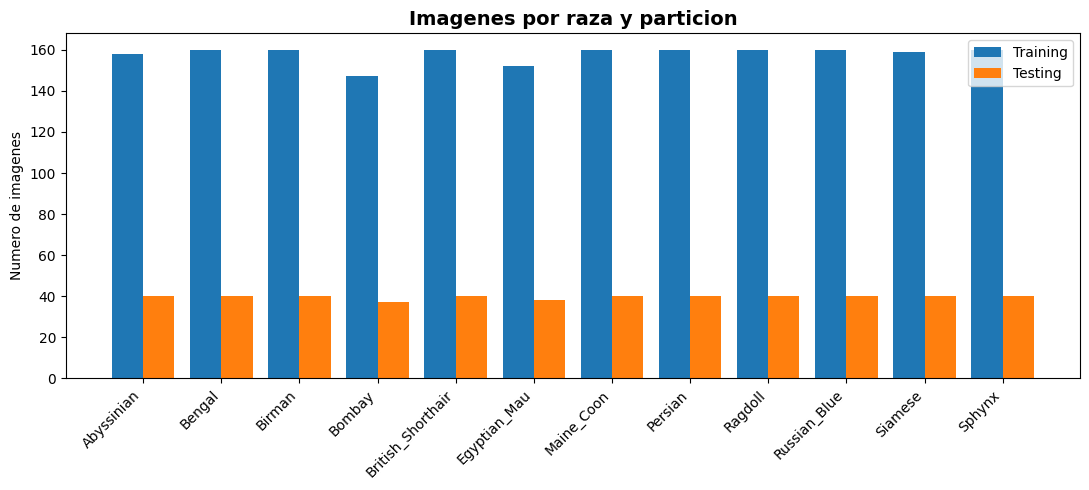

Entrenamiento: (1517, 64, 64, 3) | Validacion: (379, 64, 64, 3) | Test: (475, 64, 64, 3)


In [ ]:
descargar_dataset(URL_DATASET)
particionar_dataset()

train_ds, val_ds, test_ds, class_names = cargar_datos()
class_distribution = analizar_dataset(train_ds, class_names, mostrar=True)
datos = preprocesar(train_ds, val_ds, test_ds)
NUM_CLASSES = datos["num_clases"]

In [ ]:
verificar_particion(train_ds, val_ds)

Archivos en entrenamiento: 1517 | en validacion: 379
Sin solapamiento: True


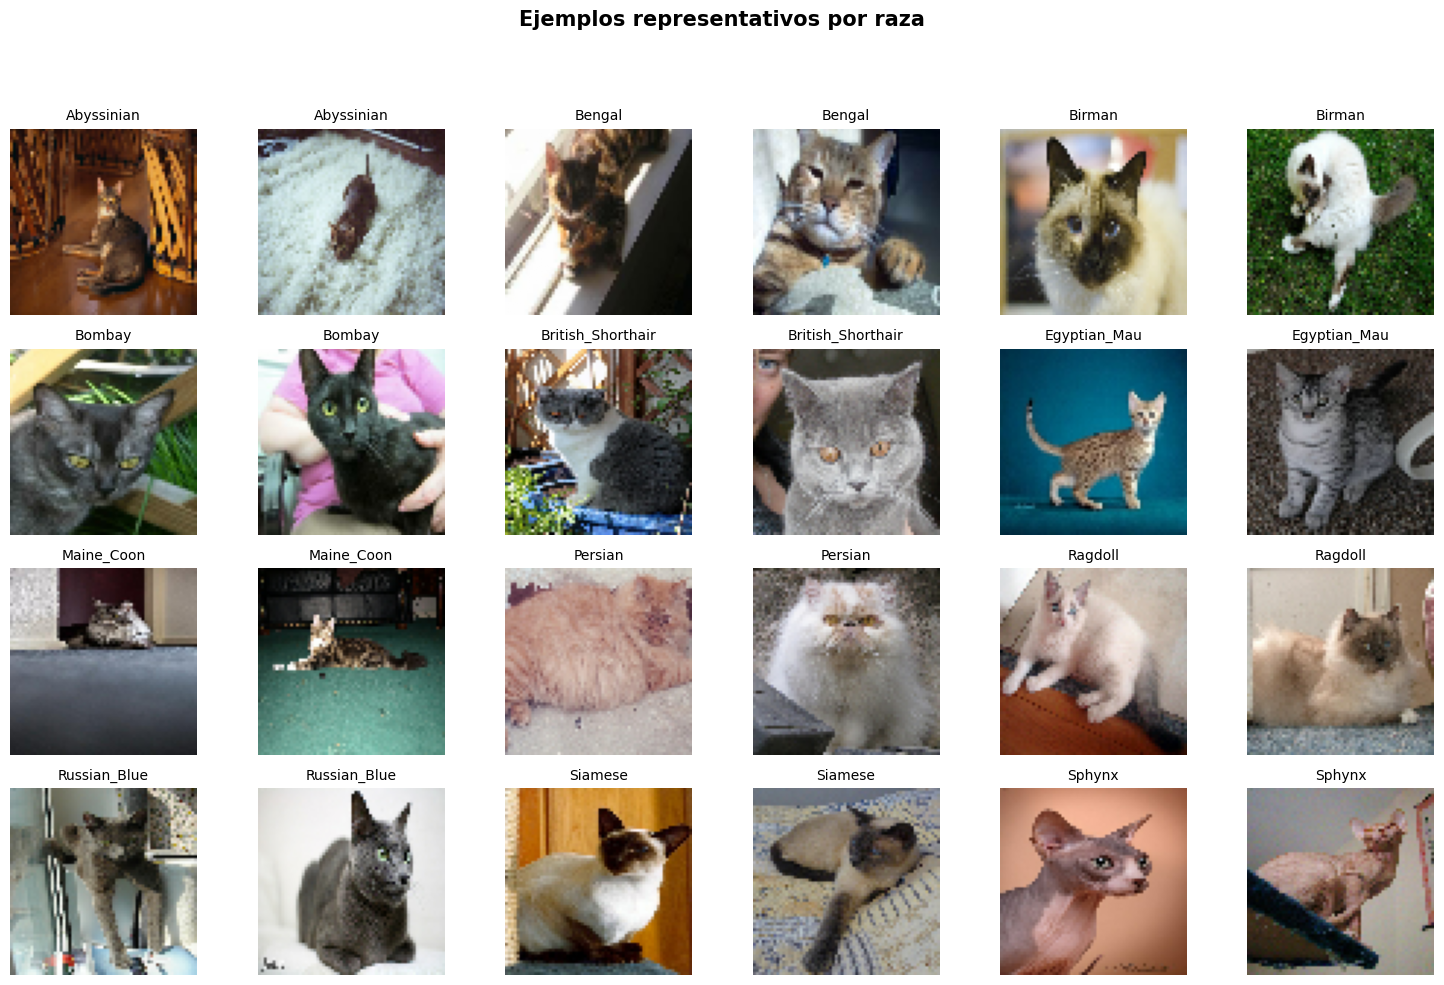

In [ ]:
mostrar_ejemplos_por_raza(datos["X_train"], datos["y_train"], class_names)

La tabla anterior y los ejemplos permiten revisar las doce razas y comprobar su distribución. El número de archivos por clase no es suficiente para garantizar un desempeño equilibrado: también hay que revisar la precisión, recall y F1 por raza en prueba.

Las imágenes se normalizan a [0, 1] y la resolución 64 × 64 permite entrenamientos accesibles, pero puede eliminar detalles de la cara o el pelaje. Se registran las cantidades de imágenes en la propia ejecución, por lo que no dependemos de cifras copiadas de entrenamientos anteriores.


## 3. Construcción de las arquitecturas

construir_modelo() conserva la lógica de los trabajos anteriores: tres bloques de convolución para la CNN y capas densas para la MLP. Ambas comparten dimensiones, pérdida, optimizador de referencia y particiones para poder comparar resultados.

| Decisión de partida | CNN | MLP |
|---|---|---|
| Entrada | RGB de 64 × 64 × 3 | RGB de 64 × 64 × 3 |
| Extracción | Conv2D con 16, 32 y 64 filtros + ReLU + MaxPooling | Flatten al inicio |
| Capas densas | 128 neuronas | 128 y 64 neuronas |
| Salida | Softmax de 12 clases | Softmax de 12 clases |
| Pérdida | sparse_categorical_crossentropy | La misma |
| Optimizador inicial | Adam, LR 0,001 | Adam, LR 0,001 |
| Lote y máximo de épocas | 32 y 30 | 32 y 30 |

Por qué partimos de estos valores: los tres bloques y filtros provienen de la CNN de la E2; las capas densas, del diseño de la MLP de la E1. Adam, lote 32 y 30 épocas se mantienen como una referencia común, no como valores demostrados óptimos. En la sección 7 probamos tasas de aprendizaje, tamaños de lote y, para la CNN, filtros y neuronas. Se mantiene fijo el número de bloques y el optimizador para acotar el costo de la búsqueda.

La activación ReLU se implementa como una capa separada para insertar Batch Normalization antes de ella sin cambiar los tres bloques principales. Para la inicialización se comparan Glorot y He; el optimizador utilizado es Adam. Los model.summary() siguientes muestran la arquitectura y los parámetros reales de cada modelo.

In [ ]:
def construir_modelo(tipo_modelo, regularizacion, tecnicas, hp, num_clases,
                     input_shape=(64, 64, 3), semilla=SEED):
    """
    Construye y compila la CNN o la MLP

    Parametros
    ----------
    tipo_modelo : {"CNN", "MLP"}
    regularizacion : bool
        False = modelo base, sin tecnicas de regularizacion
    tecnicas : tuple de str
        Técnicas activas, subconjunto de TECNICAS_ESTUDIADAS. Solo actuan si regularizacion es True
    hp : dict
        Hiperparametros Solo se usan los de las técnicas activas
    num_clases : int
        Neuronas de salida
    input_shape, semilla : tupla, int
        Forma de la imagen y semilla de los pesos iniciales

    Returns
    -------
    keras.Sequential compilado con Adam y sparse_categorical_crossentropy
    """
    if tipo_modelo not in ("CNN", "MLP"):
        raise ValueError("tipo_modelo debe ser 'CNN' o 'MLP'")
    tecnicas = tuple(tecnicas) if regularizacion else ()


    tf.keras.utils.set_random_seed(semilla)

    init = initializers.HeNormal(seed=semilla) if "He" in tecnicas else "glorot_uniform"
    if "L1 (Lasso)" in tecnicas and "L2" in tecnicas:
        reg = regularizers.l1_l2(l1=hp["l1"], l2=hp["l2"])
    elif "L1 (Lasso)" in tecnicas:
        reg = regularizers.l1(hp["l1"])
    elif "L2" in tecnicas:
        reg = regularizers.l2(hp["l2"])
    else:
        reg = None
    bn = "Batch Normalization" in tecnicas
    dropout = "Dropout" in tecnicas

    capas = [layers.Input(shape=input_shape, name="Entrada")]
    if "Data Augmentation" in tecnicas:

        capas.append(crear_aumento_datos(semilla=semilla))

    if tipo_modelo == "CNN":
        for i, filtros in enumerate(hp["filtros"], start=1):
            capas.append(layers.Conv2D(filtros, (3, 3), use_bias=not bn,
                                       kernel_initializer=init, kernel_regularizer=reg,
                                       name=f"Convolucion_{i}"))
            if bn:
                capas.append(layers.BatchNormalization(name=f"BatchNorm_conv_{i}"))
            capas.append(layers.Activation("relu", name=f"ReLU_conv_{i}"))
            capas.append(layers.MaxPooling2D((2, 2), name=f"Pooling_{i}"))
        if dropout:
            capas.append(layers.Dropout(hp["dropout_conv"], name="Dropout_conv"))
        capas.append(layers.Flatten(name="Aplanado"))
        unidades_ocultas = [hp["neuronas"]]
    else:
        capas.append(layers.Flatten(name="Aplanado"))
        unidades_ocultas = list(hp["capas_mlp"])

    for j, unidades in enumerate(unidades_ocultas, start=1):
        capas.append(layers.Dense(unidades, use_bias=not bn, kernel_initializer=init,
                                  kernel_regularizer=reg, name=f"Densa_{j}"))
        if bn:
            capas.append(layers.BatchNormalization(name=f"BatchNorm_densa_{j}"))
        capas.append(layers.Activation("relu", name=f"ReLU_densa_{j}"))
        if dropout:
            capas.append(layers.Dropout(hp["dropout_dense"], name=f"Dropout_densa_{j}"))

    capas.append(layers.Dense(num_clases, activation="softmax",
                              kernel_initializer="glorot_uniform", name="Salida"))

    modelo = keras.Sequential(capas, name=f"{tipo_modelo}_Gatos")
    modelo.compile(optimizer=optimizers.Adam(learning_rate=hp["learning_rate"]),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo

In [ ]:
cnn_demo = construir_modelo("CNN", False, (), HP_BASE, NUM_CLASSES)
mlp_demo = construir_modelo("MLP", False, (), HP_BASE, NUM_CLASSES)

print("=== ARQUITECTURA CNN BASE ===")
cnn_demo.summary()

print("\n=== ARQUITECTURA MLP BASE ===")
mlp_demo.summary()

=== ARQUITECTURA CNN BASE ===


Model: "CNN_Gatos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Convolucion_1 (Conv2D)          │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_conv_1 (Activation)        │ (None, 62, 62, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_1 (MaxPooling2D)        │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_2 (Conv2D)          │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_conv_2 (Activation)        │ (None, 29, 29, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_2 (MaxPooling2D)        │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_3 (Conv2D)          │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_conv_3 (Activation)        │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_3 (MaxPooling2D)        │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Aplanado (Flatten)              │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_1 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_densa_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida (Dense)                  │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,172 (1.22 MB)

 Trainable params: 320,172 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Aplanado (Flatten)              │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_1 (Dense)                 │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_densa_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_densa_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida (Dense)                  │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,582,028 (6.03 MB)

 Trainable params: 1,582,028 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Técnicas de entrenamiento y regularización

Comparamos cada técnica por separado frente a la misma CNN de referencia, manteniendo los datos, el diseño base y el máximo de épocas. El objetivo es observar su efecto con métricas y curvas antes de seleccionar una combinación.

| Técnica | Función | Qué comprobamos |
|---|---|---|
| Dropout | Desactiva aleatoriamente unidades al entrenar. | Si controla el sobreajuste. |
| Data Augmentation | Introduce transformaciones moderadas de imagen. | Si mejora la generalización a fotografías distintas. |
| Batch Normalization | Normaliza activaciones intermedias. | Si estabiliza y mejora la validación. |
| L2 (Ridge) | Penaliza pesos grandes. | Si reduce la complejidad de la red. |
| L1 (Lasso) | Penaliza magnitudes absolutas de pesos. | Si aporta frente a L2. |
| EarlyStopping | Detiene el aprendizaje según val_loss y restaura los mejores pesos. | Si evita entrenar épocas que empeoran la validación. |
| Inicialización He | Elige cómo comienzan los pesos con ReLU. | Si mejora el entrenamiento; **no es regularización**. |

El criterio principal para seleccionar configuraciones es la cross-entropy de validación, calculada sobre predicciones y sin penalizaciones L1/L2. La val_loss de Keras puede incluirlas; se conserva para analizar curvas y controlar EarlyStopping. También revisamos accuracy, F1 macro, tiempo y brecha entrenamiento-validación.

Una técnica útil por separado no garantiza una mejor combinación. Probamos una única combinación candidata y comprobamos su resultado antes de optimizar la MLP y la CNN.


## 5. Entrenamiento y curvas de aprendizaje

La función entrenar() utiliza fit() para las dos arquitecturas y registra épocas, tiempo y curvas. Si activamos EarlyStopping, se restauran los pesos de la menor val_loss; de otro modo, el modelo conserva los pesos de la última época. Después, para comparar sobreajuste, calculamos accuracy de entrenamiento y validación en modo inferencia, sin las transformaciones aleatorias de entrenamiento.

Primero entrenamos una CNN sin regularización para obtener una referencia. El diagnóstico siguiente se calcula de la ejecución actual.


In [ ]:
def entrenar(modelo, X_train, y_train, X_val, y_val, regularizacion, tecnicas,
             epochs=EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE, verbose=0):
    """
    Entrena el modelo con model.fit()

    Si la tecnica EarlyStopping esta activa, se usa sobre val_loss con
    restore_best_weights=True: el modelo queda con los pesos de la mejor epoca.
    Si no, el modelo queda con los pesos de la ultima epoca

    Returns
    -------
    modelo : keras.Sequential entrenado
    history : dict con las curvas por epoca
    res : dict con tiempo_s, epocas, mejor_epoca, train_acc, val_acc y val_loss
    """
    tecnicas = tuple(tecnicas) if regularizacion else ()
    usa_es = "EarlyStopping" in tecnicas
    callbacks = []
    if usa_es:
        callbacks.append(EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))

    t0 = time()
    hist = modelo.fit(X_train, y_train, epochs=epochs, batch_size=batch_size,
                      validation_data=(X_val, y_val), callbacks=callbacks, verbose=verbose)
    tiempo = time() - t0

    h = hist.history
    idx = int(np.argmin(h["val_loss"])) if usa_es else len(h["loss"]) - 1
    res = {
        "tiempo_s": tiempo,
        "epocas": len(h["loss"]),
        "mejor_epoca": idx + 1,
        "train_acc": h["accuracy"][idx],
        "val_acc": h["val_accuracy"][idx],
        "val_loss": h["val_loss"][idx],
    }
    return modelo, h, res



def graficar_curvas(history, nombre, titulo):
    """
    Curvas de aprendizaje de un entrenamiento: una figura para la perdida y otra para la accuracy,
    cada una con la curva de entrenamiento y la de validacion. La linea gris marca el minimo de val_loss
    """
    mejor = int(np.argmin(history["val_loss"]))
    for metrica, etiqueta, sufijo in [("loss", "Pérdida", "perdida"), ("accuracy", "Accuracy", "accuracy")]:
        plt.figure(figsize=(8, 5))
        plt.plot(history[metrica], label="Entrenamiento")
        plt.plot(history[f"val_{metrica}"], label="Validacion")
        plt.axvline(mejor, color="gray", ls="--", label=f"Minimo de val_loss (epoca {mejor + 1})")
        plt.title(f"{titulo}: {etiqueta.lower()}", fontweight="bold")
        plt.xlabel("Epocas")
        plt.ylabel(etiqueta)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        guardar(f"{nombre}_{sufijo}")
        plt.show()



def evaluar_aprendizaje(history, nombre, mostrar=True, indice=None, train_inf=None, val_inf=None):
    """
    Diagnóstico de las curvas de aprendizaje

    indice: epoca utilizada para evaluar el modelo
    Con EarlyStopping se usa la mejor epoca; sin el, la ultima
    Si es None, se usa la epoca con menor val_loss

    Para detectar sobreajuste o subajuste, se evaluan los conjuntos
    en modo inferencia, sin Dropout ni Data Augmentation

    Returns
    -------
    dict con mejor_epoca (epoca evaluada), train_acc, val_acc, brecha y diagnostico.
    """
    minimo = int(np.argmin(history["val_loss"]))
    evaluada = minimo if indice is None else indice
    tr, va = history["accuracy"][evaluada], history["val_accuracy"][evaluada]
    brecha = (train_inf - val_inf) if train_inf is not None and val_inf is not None else np.nan
    if np.isnan(brecha):
        diagnostico = "sin diagnostico comparable (falta modo inferencia)"
    elif brecha > 0.15:
        diagnostico = "brecha notable train-val: revisar sobreajuste"
    elif brecha > 0.05:
        diagnostico = "brecha moderada train-val: revisar sobreajuste"
    else:
        diagnostico = "brecha train-val pequeña; no prueba ausencia de subajuste"
    if mostrar:
        graficar_curvas(history, slug(nombre), nombre)
        print(f"Época evaluada: {evaluada + 1} (mínimo de val_loss en la época {minimo + 1})")
        print(f"Accuracy registrada en fit: train={tr:.3f}, val={va:.3f}")
        if not np.isnan(brecha):
            print(f"Accuracy en inferencia: train={train_inf:.3f}, val={val_inf:.3f}; brecha={brecha:.3f}")
        print(f"Diagnóstico: {diagnostico}")
    return {"mejor_epoca": evaluada + 1, "train_acc": tr, "val_acc": va,
            "brecha": brecha, "diagnostico": diagnostico,
            "train_acc_inferencia": train_inf, "val_acc_inferencia": val_inf}




def ejecutar_experimento(nombre, tipo_modelo, regularizacion, tecnicas, hp, datos, epochs=EPOCHS,
                         semilla=SEED):
    """
    Construye, entrena y evalúa un modelo utilizando el conjunto de validacion

    Returns
    -------
    dict con nombre, modelo, history, res y fila (una fila del registro de experimentos)
    """
    tecnicas = tuple(tecnicas) if regularizacion else ()
    modelo = construir_modelo(tipo_modelo, regularizacion, tecnicas, hp, datos["num_clases"],
                              semilla=semilla)
    modelo, history, res = entrenar(modelo, datos["X_train"], datos["y_train"],
                                    datos["X_val"], datos["y_val"], regularizacion, tecnicas,
                                    epochs=epochs, batch_size=hp["batch_size"], patience=hp["patience"])
    probs_val = modelo.predict(datos["X_val"], verbose=0)
    pred_val = np.argmax(probs_val, axis=1)
    val_prec = precision_score(datos["y_val"], pred_val, average="macro", zero_division=0)
    val_rec = recall_score(datos["y_val"], pred_val, average="macro", zero_division=0)
    val_f1 = f1_score(datos["y_val"], pred_val, average="macro", zero_division=0)
    val_ce = log_loss(datos["y_val"], probs_val, labels=np.arange(datos["num_clases"]))
    val_auc = roc_auc_score(datos["y_val"], probs_val, multi_class="ovr", average="macro")
    fila = {
        "Experimento": nombre,
        "Arquitectura": tipo_modelo,
        "Técnicas": " + ".join(tecnicas) if tecnicas else "ninguna",
        "Val loss": res["val_loss"],
        "Val CE": val_ce,
        "Val accuracy": res["val_acc"],
        "Val precision": val_prec,
        "Val recall": val_rec,
        "Val F1": val_f1,
        "Val ROC AUC": val_auc,
        "Brecha train-val (fit)": res["train_acc"] - res["val_acc"],
        "Épocas": res["epocas"],
        "Mejor época": res["mejor_epoca"],
        "Tiempo (s)": res["tiempo_s"],
        "Parámetros": modelo.count_params(),
        "LR": hp["learning_rate"],
        "Batch": hp["batch_size"],
        "Dropout": hp["dropout_dense"] if "Dropout" in tecnicas else None,
        "L2": hp["l2"] if "L2" in tecnicas else None,
        "L1": hp["l1"] if "L1 (Lasso)" in tecnicas else None,
        "Neuronas": hp["neuronas"] if tipo_modelo == "CNN" else None,
        "Filtros": str(hp["filtros"]) if tipo_modelo == "CNN" else None,
    }
    return {"nombre": nombre, "modelo": modelo, "history": history, "res": res, "fila": fila}

### 5.1 CNN base para el estudio

Entrenamos una CNN sin regularización. Su historial permite observar qué ocurre cuando la red aprende las imágenes de entrenamiento sin medidas adicionales para controlar el sobreajuste.

Epocas ejecutadas: 30 de 30 | Tiempo: 224.9 s


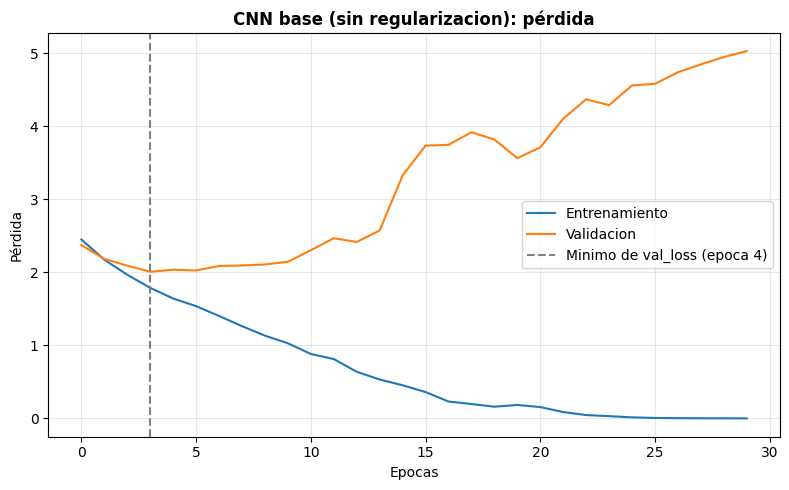

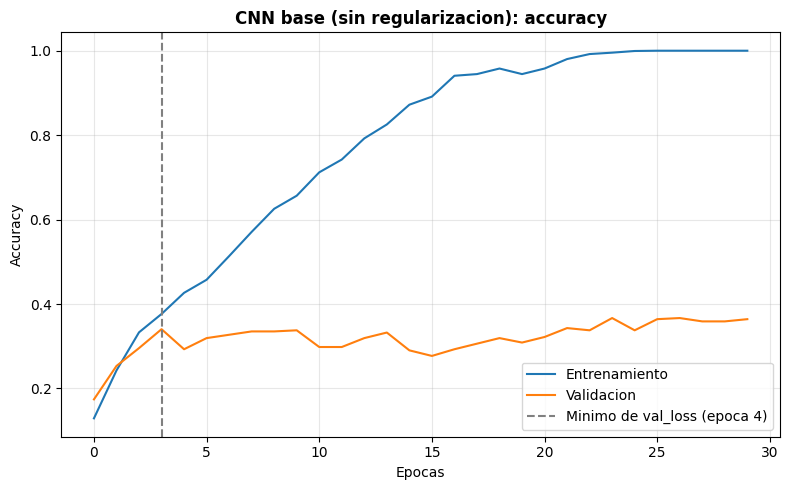

Época evaluada: 30 (mínimo de val_loss en la época 4)
Accuracy registrada en fit: train=1.000, val=0.364
Accuracy en inferencia: train=1.000, val=0.364; brecha=0.636
Diagnóstico: brecha notable train-val: revisar sobreajuste
CNN base: train accuracy final=1.000; val accuracy final=0.364; época de menor val_loss=4; épocas ejecutadas=30.


In [ ]:
exp_base = ejecutar_experimento("CNN base (sin regularizacion)", "CNN", False, (), HP_BASE, datos)
print(f"Epocas ejecutadas: {exp_base['res']['epocas']} de {EPOCHS} | Tiempo: {exp_base['res']['tiempo_s']:.1f} s")
modelo_base = exp_base["modelo"]
_, train_inf_base = modelo_base.evaluate(
    datos["X_train"], datos["y_train"], verbose=0
)
_, val_inf_base = modelo_base.evaluate(
    datos["X_val"], datos["y_val"], verbose=0
)
diag_base = evaluar_aprendizaje(
    exp_base["history"],
    "CNN base (sin regularizacion)",
    indice=exp_base["res"]["epocas"] - 1,
    train_inf=float(train_inf_base),
    val_inf=float(val_inf_base)
)
h_base = exp_base["history"]
print(f"CNN base: train accuracy final={h_base['accuracy'][-1]:.3f}; "
      f"val accuracy final={h_base['val_accuracy'][-1]:.3f}; "
      f"época de menor val_loss={int(np.argmin(h_base['val_loss'])) + 1}; "
      f"épocas ejecutadas={exp_base['res']['epocas']}.")


### 5.2 Análisis de la CNN base
La CNN base completó las 30 épocas y alcanzó una accuracy de 100% en entrenamiento, pero solo 36,4% en validación, según las métricas registradas durante el entrenamiento.

La menor pérdida de validación apareció en la época 4. Sin embargo, el modelo continuó entrenándose hasta la época 30 y conservó los pesos de esta última, mostrando un sobreajuste importante.

Por esta razón, probamos diferentes técnicas de regularización para mejorar la generalización. También utilizamos EarlyStopping para comprobar si detener el entrenamiento antes permitía obtener mejores resultados de validación.

Las curvas muestran que aprender correctamente las imágenes de entrenamiento no garantiza un buen rendimiento con imágenes que el modelo no ha visto.


## 6. Regularización: comparación individual

Partimos de una CNN sin técnicas adicionales y realizamos siete ensayos separados: Dropout, Data Augmentation, Batch Normalization, L2 (Ridge), L1 (Lasso), EarlyStopping e inicialización He. En cada ensayo activamos una sola técnica y mantenemos los demás parámetros.

La tabla compara accuracy, F1 macro, cross-entropy de validación, pérdida de Keras, número de épocas y tiempo. Una menor Val CE indica mejor desempeño predictivo según el criterio escogido; también revisamos F1 para no depender de una sola cifra.

Tomamos hasta tres técnicas que mejoren la Val CE de la base. Si aparecen L1 y L2, solo se conserva la mejor entre ellas. Entrenamos una combinación con las técnicas candidatas y la comparamos con la mejor prueba individual. Si no mejora, conservamos la alternativa individual. Esta comprobación es necesaria porque los efectos individuales no garantizan un efecto conjunto.

La selección se realiza con validación, nunca con prueba.

In [ ]:
def estudio_individual(datos, base, hp, tecnicas_estudiadas, epochs=EPOCHS):
    """Evalua una tecnica por entrenamiento con hiperparametros recibidos por argumento."""
    experimentos = {}
    ce_base = base["fila"]["Val CE"]
    filas = [{**base["fila"], "Cambio Val CE vs base": 0.0}]
    for tecnica in tecnicas_estudiadas:
        exp = ejecutar_experimento(
            f"CNN | {tecnica}", "CNN", True, (tecnica,), hp, datos, epochs
        )
        experimentos[tecnica] = exp
        filas.append({**exp["fila"],
                      "Cambio Val CE vs base": exp["fila"]["Val CE"] - ce_base})
    tabla = pd.DataFrame(filas).sort_values("Val CE").reset_index(drop=True)
    return tabla, experimentos


def seleccionar_regularizacion(datos, base, individuales, hp, max_tecnicas=3, epochs=EPOCHS):
    """Elige candidatos por pruebas individuales y confirma una sola combinacion
    Recibe los hiperparametros explicitamente para evitar dependencias globales
    El criterio principal es la menor cross-entropy de validación (Val CE)
    L1 y L2 se prueban por separado, pero no se mezclan en esta seleccion
    La combinación solo se mantiene si mejora a la mejor opcion individual

    Returns
    -------
    tecnicas_finales : tuple
    seleccion : DataFrame con alternativas comparadas
    exp_elegido : experimento validado, base, individual o combinación
    exp_combinado : experimento de combinación, o None cuando no procede
    """
    ce_base = float(base["fila"]["Val CE"])
    orden = sorted(individuales, key=lambda t: individuales[t]["fila"]["Val CE"])
    candidatos = []
    for tecnica in orden:
        if float(individuales[tecnica]["fila"]["Val CE"]) >= ce_base:
            continue
        if tecnica in ("L1 (Lasso)", "L2") and any(t in candidatos for t in ("L1 (Lasso)", "L2")):
            continue
        candidatos.append(tecnica)
        if len(candidatos) >= max_tecnicas:
            break

    mejor_individual = min(individuales, key=lambda t: individuales[t]["fila"]["Val CE"])
    exp_elegido = base
    tecnicas_finales = ()
    if float(individuales[mejor_individual]["fila"]["Val CE"]) < ce_base:
        exp_elegido = individuales[mejor_individual]
        tecnicas_finales = (mejor_individual,)

    exp_combinado = None
    if len(candidatos) >= 2:
        exp_combinado = ejecutar_experimento(
            "CNN | combinacion candidata", "CNN", True, tuple(candidatos),
            hp, datos, epochs
        )
        if float(exp_combinado["fila"]["Val CE"]) < float(exp_elegido["fila"]["Val CE"]):
            exp_elegido = exp_combinado
            tecnicas_finales = tuple(candidatos)

    alternativas = [
        {"Alternativa": "CNN base", "Técnicas": "ninguna",
         "Val CE": ce_base, "Val F1": base["fila"]["Val F1"]},
        {"Alternativa": "Mejor individual", "Técnicas": mejor_individual,
         "Val CE": individuales[mejor_individual]["fila"]["Val CE"],
         "Val F1": individuales[mejor_individual]["fila"]["Val F1"]},
    ]
    if exp_combinado is not None:
        alternativas.append({"Alternativa": "Combinación candidata",
                             "Técnicas": " + ".join(candidatos),
                             "Val CE": exp_combinado["fila"]["Val CE"],
                             "Val F1": exp_combinado["fila"]["Val F1"]})
    tabla = pd.DataFrame(alternativas)
    tabla["Seleccionada"] = tabla["Técnicas"].apply(
        lambda t: "sí" if t == (" + ".join(tecnicas_finales) or "ninguna") else "no"
    )
    return tecnicas_finales, tabla, exp_elegido, exp_combinado

In [ ]:

tabla_individual, experimentos_individuales = estudio_individual(
    datos, exp_base, hp=HP_BASE, tecnicas_estudiadas=TECNICAS_ESTUDIADAS
)
columnas_individual = [
    "Experimento", "Val accuracy", "Val F1", "Val CE", "Val loss",
    "Cambio Val CE vs base", "Mejor época", "Tiempo (s)"
]
print("Regularización: una técnica por experimento (menor Val CE = mejor):")
display(tabla_individual[columnas_individual].round(4))

TECNICAS_SELECCIONADAS, tabla_seleccion, exp_seleccionada, exp_combinacion = seleccionar_regularizacion(
    datos, exp_base, experimentos_individuales, hp=HP_BASE
)
print("\nComprobacion de la configuracion elegida:")
display(tabla_seleccion.round(4))
print("Tecnicas elegidas para optimizacion:",
      " + ".join(TECNICAS_SELECCIONADAS) or "ninguna")

filas_reg = tabla_individual.drop(
    columns=["Cambio Val CE vs base"]
).to_dict(orient="records")

if exp_combinacion is not None:
    filas_reg.append(exp_combinacion["fila"].copy())

registro_regularizacion = pd.DataFrame(filas_reg)
mejor_fila = tabla_individual.loc[tabla_individual["Val CE"].idxmin()]
ce_base_reg = float(exp_base["fila"]["Val CE"])
print(f"Referencia CNN: Val CE={ce_base_reg:.4f}; "
      f"mejor ensayo individual={mejor_fila['Experimento']} "
      f"(Val CE={float(mejor_fila['Val CE']):.4f}).")
if exp_combinacion is not None:
    ce_combinada = float(exp_combinacion["fila"]["Val CE"])
    print(f"Combinación candidata: Val CE={ce_combinada:.4f}; "
          f"diferencia frente al mejor individual={float(mejor_fila['Val CE'])-ce_combinada:+.4f} "
          f"(valor positivo favorece la combinacion).")
print("Candidata elegida para la etapa 7:", " + ".join(TECNICAS_SELECCIONADAS) or "ninguna")


Regularización: una técnica por experimento (menor Val CE = mejor):


,Experimento,Val accuracy,Val F1,Val CE,Val loss,Cambio Val CE vs base,Mejor época,Tiempo (s)
0,CNN | EarlyStopping,0.3404,0.3409,2.0099,2.0099,-2.6712,4,75.0746
1,CNN | Data Augmentation,0.3113,0.2916,2.2548,2.2548,-2.4264,30,277.1133
2,CNN | Batch Normalization,0.3483,0.3490,2.4470,2.4470,-2.2341,30,265.3278
3,CNN | Dropout,0.3720,0.3624,2.5233,2.5461,-2.1578,30,226.9804
4,CNN | L2,0.3773,0.3763,4.4069,4.7595,-0.2743,30,218.1675
5,CNN | L1 (Lasso),0.3641,0.3660,4.5261,4.9797,-0.1550,30,231.4475
6,CNN | He,0.3852,0.3856,4.6426,4.9433,-0.0385,30,226.3273
7,CNN base (sin regularizacion),0.3641,0.3672,4.6811,5.0312,0.0000,30,222.1053



Comprobacion de la configuracion elegida:


,Alternativa,Técnicas,Val CE,Val F1,Seleccionada
0,CNN base,ninguna,4.6811,0.3672,no
1,Mejor individual,EarlyStopping,2.0099,0.3409,no
2,Combinación candidata,EarlyStopping + Data Augmentation + Batch Norm...,1.8189,0.3709,sí


Tecnicas elegidas para optimizacion: EarlyStopping + Data Augmentation + Batch Normalization
Referencia CNN: Val CE=4.6811; mejor ensayo individual=CNN | EarlyStopping (Val CE=2.0099).
Combinación candidata: Val CE=1.8189; diferencia frente al mejor individual=+0.1910 (valor positivo favorece la combinacion).
Candidata elegida para la etapa 7: EarlyStopping + Data Augmentation + Batch Normalization


### 6.1 Interpretación de la regularización

La tabla compara los siete ensayos individuales y la CNN base. Distinguimos los resultados de EarlyStopping, Data Augmentation, Batch Normalization, Dropout, L1, L2 e inicialización He; esta última no es una técnica de regularización. Un descenso de Val CE es favorable según nuestro criterio, pero no implica que accuracy o F1 también mejoren.

La combinación candidata utiliza como máximo tres técnicas que superaron la referencia en validación. Por eso es posible que una técnica como Dropout quede fuera a pesar de haber mejorado la CNN base: el límite de candidatas se fijó para evitar combinaciones excesivas y se eligió según Val CE, no por preferencia personal. EarlyStopping también cambia qué época se conserva, por lo que su comparación con modelos que terminan todas las épocas requiere cuidado.

La combinación de EarlyStopping, Data Augmentation y Batch Normalization obtuvo una Val CE de 1,8189, mientras que EarlyStopping por separado consiguió 2,0099. La diferencia fue de 0,1910 a favor de la combinación. Frente a la CNN base, que obtuvo 4,6811, la mejora en pérdida de validación fue mucho mayor.

Al repetir una configuración equivalente al comienzo de la optimización obtuvimos nuevamente 1,8189. Esto muestra consistencia entre esas dos ejecuciones, pero no permite medir la variabilidad del entrenamiento porque utilizamos una semilla fija. Para comprobar si las mejoras se mantienen sería necesario repetir los experimentos con otras semillas.

Elegimos la combinación por su menor Val CE, pero no afirmamos que sea superior en todas las métricas ni en cualquier ejecución.


### 6.2 Curvas de aprendizaje

Las siguientes curvas muestran el entrenamiento de la CNN base y cada técnica individual. Observamos tanto la evolución de la pérdida como la accuracy de validación, y comparamos la configuración elegida con la base. No hace falta entrenar de nuevo para generar estas figuras: usamos los historiales ya guardados.

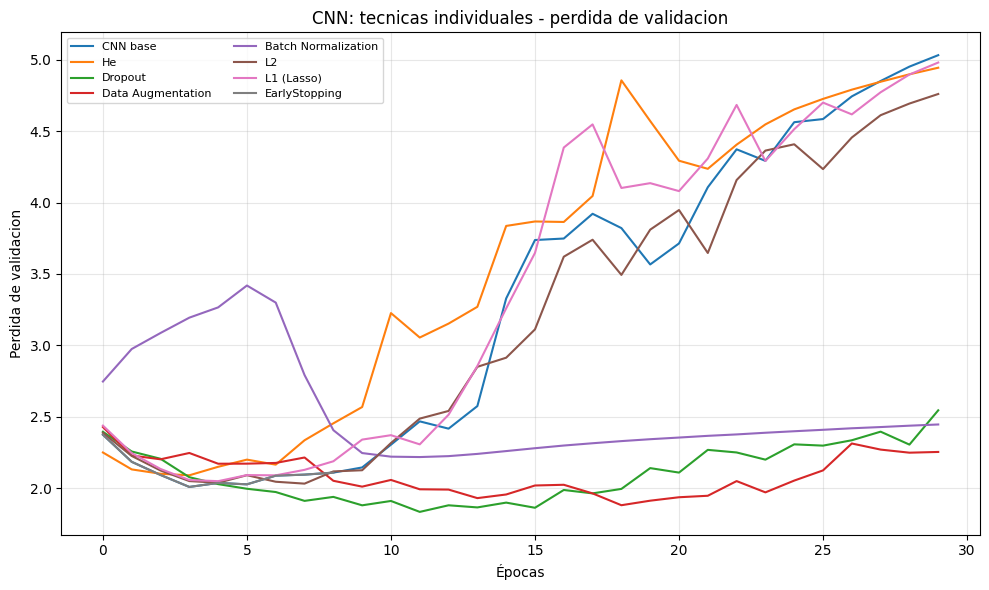

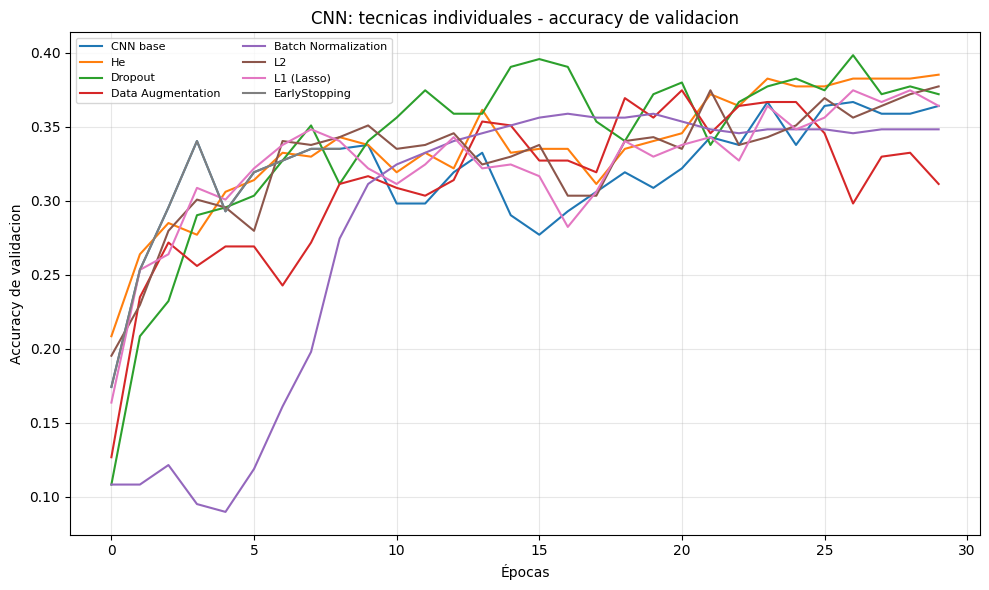

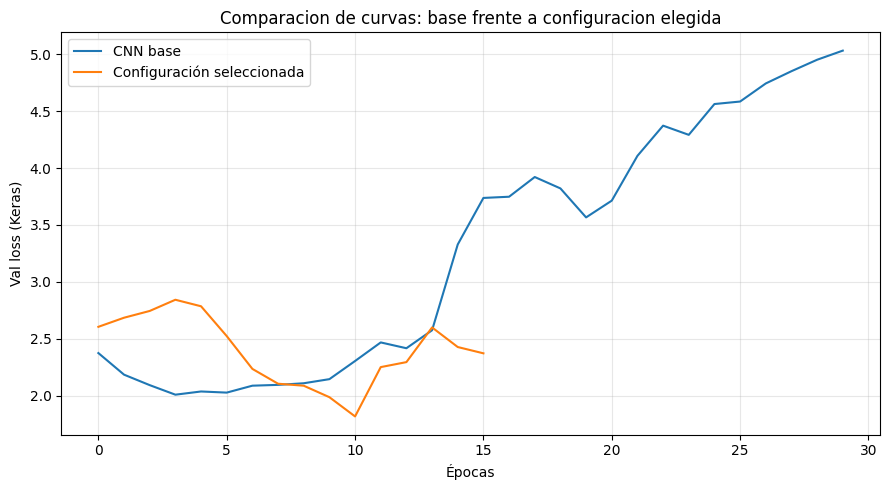

In [ ]:
def graficar_comparaciones_individuales(base, individuales, seleccionada):
    """Grafica las curvas de validacion de la base, ensayos individuales y seleccion"""
    curvas = [("CNN base", base)] + [(t, individuales[t]) for t in TECNICAS_ESTUDIADAS]
    for metrica, etiqueta, sufijo in [
        ("val_loss", "Perdida de validacion", "perdida"),
        ("val_accuracy", "Accuracy de validacion", "accuracy"),
    ]:
        plt.figure(figsize=(10, 6))
        for nombre, exp in curvas:
            plt.plot(exp["history"][metrica], label=nombre)
        plt.xlabel("Épocas")
        plt.ylabel(etiqueta)
        plt.title(f"CNN: tecnicas individuales - {etiqueta.lower()}")
        plt.grid(True, alpha=0.3)
        plt.legend(fontsize=8, ncol=2)
        plt.tight_layout()
        guardar(f"regularizacion_individual_{sufijo}")
        plt.show()

    if seleccionada["nombre"] != base["nombre"]:
        plt.figure(figsize=(9, 5))
        plt.plot(base["history"]["val_loss"], label="CNN base")
        plt.plot(seleccionada["history"]["val_loss"], label="Configuración seleccionada")
        plt.xlabel("Épocas")
        plt.ylabel("Val loss (Keras)")
        plt.title("Comparacion de curvas: base frente a configuracion elegida")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        guardar("regularizacion_base_vs_elegida")
        plt.show()


graficar_comparaciones_individuales(exp_base, experimentos_individuales, exp_seleccionada)

### 6.3 Inicialización He frente a Glorot

Probamos la inicialización He porque la CNN utiliza ReLU y la comparamos con Glorot, que es la referencia. Los resultados aparecen en la tabla de la sección 6. La inicialización no debe confundirse con regularización: modifica los pesos iniciales, pero no introduce una penalización ni detiene el entrenamiento. Si He no reduce la Val CE respecto a la base, no se incorpora a la combinación. Con una sola ejecución no podemos asegurar que una inicialización sea siempre superior.


## 7. Optimización de hiperparámetros

### 7.1 Estrategia y plan de experimentos

Con las técnicas elegidas optimizamos por separado la CNN y la MLP, usando únicamente validación para comparar configuraciones.

- **OFAT:** modifica un hiperparámetro a la vez, mantiene el mejor valor encontrado y continúa con el siguiente. Permite observar el efecto de un cambio controlado.
- **Random Search:** prueba cinco combinaciones aleatorias reproducibles por arquitectura. Explora valores simultáneamente sin recorrer una rejilla completa.

Se prueban tasas de aprendizaje y tamaños de lote en ambas arquitecturas. En CNN también varían filtros y neuronas; los valores de Dropout, L1 y L2 solamente se ajustan si esas técnicas están activas. La cantidad de bloques y Adam se mantienen fijos porque el presupuesto experimental es limitado: esto no demuestra que sean óptimos. Las tablas detallan cada configuración probada y permiten justificar la decisión.

**Hipótesis:** variar el learning rate puede mejorar la convergencia; cambiar el lote puede afectar la estabilidad y el tiempo; modificar filtros y neuronas cambia la capacidad de la CNN. La búsqueda selecciona la menor Val CE entre las pruebas realizadas, sin prometer un óptimo global ni una ventaja estadísticamente demostrada.


In [ ]:
def espacio_busqueda(tipo_modelo, tecnicas):
    """Valores acotados para cambiar un hiperparametro por vez en OFAT"""
    espacio = {
        "learning_rate": [1e-4, 5e-4, 1e-3],
        "batch_size": [32, 64],
    }
    if "Dropout" in tecnicas:
        espacio["dropout_dense"] = [0.3, 0.5]
    if "L1 (Lasso)" in tecnicas:
        espacio["l1"] = [1e-6, 1e-5]
    if "L2" in tecnicas:
        espacio["l2"] = [1e-5, 1e-4]
    if tipo_modelo == "CNN":
        espacio["neuronas"] = [64, 128]
        espacio["filtros"] = [(16, 32, 64), (32, 64, 128)]
    return espacio


def optimizar_secuencial(tipo_modelo, espacio, hp_inicial, tecnicas, datos, epochs=EPOCHS):
    """OFAT: cambia una variable, conserva el mejor valor y continua a la siguiente"""
    base = ejecutar_experimento(f"{tipo_modelo} OFAT | base", tipo_modelo, True, tecnicas,
                                hp_inicial, datos, epochs)
    hp_actual = dict(hp_inicial)
    val_actual = float(base["fila"]["Val CE"])
    filas = [base["fila"]]
    for hp_nombre, valores in espacio.items():
        mejor_valor, mejor_ce = hp_actual[hp_nombre], val_actual
        for valor in valores:
            if valor == hp_actual[hp_nombre]:
                continue
            hp_prueba = {**hp_actual, hp_nombre: valor}
            exp = ejecutar_experimento(
                f"{tipo_modelo} OFAT | {hp_nombre}={valor}", tipo_modelo, True,
                tecnicas, hp_prueba, datos, epochs
            )
            filas.append(exp["fila"])
            if float(exp["fila"]["Val CE"]) < mejor_ce:
                mejor_valor, mejor_ce = valor, float(exp["fila"]["Val CE"])
        hp_actual[hp_nombre] = mejor_valor
        val_actual = mejor_ce
        print(f"{tipo_modelo}: {hp_nombre} = {mejor_valor} (Val CE {mejor_ce:.4f})")
    return hp_actual, pd.DataFrame(filas)



N_ALEATORIO = 5
COLUMNAS_OPTIMIZACION = [
    "Método", "Experimento", "LR", "Batch", "Dropout", "L1", "L2", "Neuronas", "Filtros",
    "Val accuracy", "Val precision", "Val recall", "Val F1", "Val ROC AUC", "Val CE",
    "Val loss", "Épocas", "Tiempo (s)"
]


def describir_hp(hp, tecnicas, tipo_modelo):
    """Describe solo los hiperparametros relevantes para el ensayo"""
    claves = ["learning_rate", "batch_size"]
    if "Dropout" in tecnicas:
        claves.append("dropout_dense")
    if "L1 (Lasso)" in tecnicas:
        claves.append("l1")
    if "L2" in tecnicas:
        claves.append("l2")
    if tipo_modelo == "CNN":
        claves += ["neuronas", "filtros"]
    return ", ".join(f"{k}={hp[k]}" for k in claves)


def buscar_aleatorio(tipo_modelo, tecnicas, hp_inicial, datos, n=N_ALEATORIO,
                      epochs=EPOCHS, semilla=SEED):
    """Random Search: combina n valores dentro de rangos definidos previamente"""
    rng = np.random.default_rng(semilla)
    filas, mejor_hp, mejor_ce = [], None, np.inf
    for k in range(1, n + 1):
        hp = dict(hp_inicial)
        hp["learning_rate"] = float(10 ** rng.uniform(-4, -3))
        hp["batch_size"] = int(rng.choice([32, 64]))
        if "Dropout" in tecnicas:
            hp["dropout_dense"] = float(rng.uniform(0.3, 0.6))
        if "L1 (Lasso)" in tecnicas:
            hp["l1"] = float(10 ** rng.uniform(-6, -4))
        if "L2" in tecnicas:
            hp["l2"] = float(10 ** rng.uniform(-5, -3))
        if tipo_modelo == "CNN":
            hp["neuronas"] = int(rng.choice([64, 128]))
            hp["filtros"] = [(16, 32, 64), (32, 64, 128)][int(rng.integers(2))]
        exp = ejecutar_experimento(f"{tipo_modelo} Random | config {k}", tipo_modelo,
                                   True, tecnicas, hp, datos, epochs)
        filas.append(exp["fila"])
        if float(exp["fila"]["Val CE"]) < mejor_ce:
            mejor_hp, mejor_ce = hp, float(exp["fila"]["Val CE"])
    return mejor_hp, pd.DataFrame(filas)


def optimizar_modelo(tipo_modelo, tecnicas, hp_inicial, datos, epochs=EPOCHS):
    """Compara OFAT y Random Search en validacion; devuelve la mejor configuracion"""
    espacio = espacio_busqueda(tipo_modelo, tecnicas)
    hp_ofat, reg_ofat = optimizar_secuencial(tipo_modelo, espacio, hp_inicial,
                                            tecnicas, datos, epochs)
    hp_random, reg_random = buscar_aleatorio(tipo_modelo, tecnicas, hp_inicial,
                                            datos, epochs=epochs)
    metodos = {
        "OFAT (una variable a la vez)": (hp_ofat, reg_ofat),
        "Random Search": (hp_random, reg_random),
    }
    registro = pd.concat([reg.assign(**{"Método": m}) for m, (_, reg) in metodos.items()],
                         ignore_index=True)
    base = reg_ofat.iloc[0]
    descripcion_base = describir_hp(hp_inicial, tecnicas, tipo_modelo)
    filas = [{
        "Configuración": "Baseline (partida)", "Experimentos": 1,
        "Mejor Val CE": base["Val CE"], "Val loss": base["Val loss"],
        "Val accuracy": base["Val accuracy"], "Val precision": base["Val precision"],
        "Val recall": base["Val recall"], "Val F1": base["Val F1"],
        "Val ROC AUC": base["Val ROC AUC"],
        "Hiperparámetros": descripcion_base, "Observaciones": "punto de partida",
    }]
    for metodo, (hp, reg) in metodos.items():
        mejor = reg.loc[reg["Val CE"].idxmin()]
        filas.append({
            "Configuración": f"Mejor de {metodo}", "Experimentos": len(reg),
            "Mejor Val CE": mejor["Val CE"], "Val loss": mejor["Val loss"],
            "Val accuracy": mejor["Val accuracy"], "Val precision": mejor["Val precision"],
            "Val recall": mejor["Val recall"], "Val F1": mejor["Val F1"],
            "Val ROC AUC": mejor["Val ROC AUC"],
            "Hiperparámetros": describir_hp(hp, tecnicas, tipo_modelo),
            "Observaciones": "igual que baseline" if describir_hp(hp, tecnicas, tipo_modelo) == descripcion_base else "difiere de baseline",
        })
    resumen = pd.DataFrame(filas)
    metodo_elegido = min(metodos, key=lambda m: metodos[m][1]["Val CE"].min())
    resumen["Elegido"] = [""] + ["sí" if m == metodo_elegido else "no" for m in metodos]
    return metodos[metodo_elegido][0], resumen, registro


def graficar_optimizacion(registro, tipo_modelo):
    """Muestra las configuraciones probadas y su CE de validación por metodo."""
    orden = registro.sort_values("Val CE", ascending=False).reset_index(drop=True)
    y = np.arange(len(orden))
    colores = {"OFAT (una variable a la vez)": "steelblue", "Random Search": "seagreen"}
    plt.figure(figsize=(10, max(5, 0.33 * len(orden))))
    for metodo, color in colores.items():
        mascara = (orden["Método"] == metodo).values
        plt.scatter(orden.loc[mascara, "Val CE"], y[mascara], color=color, label=metodo, s=60)
    plt.axvline(orden["Val CE"].min(), color="gray", ls="--", label="Menor Val CE")
    plt.yticks(y, orden["Experimento"], fontsize=8)
    plt.xlabel("Cross-entropy de validación (menor es mejor)")
    plt.title(f"{tipo_modelo}: búsqueda de hiperparámetros")
    plt.legend()
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    guardar(f"07_optimizacion_{tipo_modelo.lower()}")
    plt.show()

CNN: learning_rate = 0.001 (Val CE 1.8189)
CNN: batch_size = 32 (Val CE 1.8189)
CNN: neuronas = 128 (Val CE 1.8189)
CNN: filtros = (32, 64, 128) (Val CE 1.7659)
Tabla O-A. Baseline y mejores opciones de cada método (CNN)


,Configuración,Experimentos,Mejor Val CE,Val loss,Val accuracy,Val precision,Val recall,Val F1,Val ROC AUC,Hiperparámetros,Observaciones,Elegido
0,Baseline (partida),1,1.8189,1.8189,0.3826,0.3847,0.3812,0.3709,0.8455,"learning_rate=0.001, batch_size=32, neuronas=1...",punto de partida,
1,Mejor de OFAT (una variable a la vez),6,1.7659,1.7659,0.3984,0.4392,0.4043,0.3920,0.8508,"learning_rate=0.001, batch_size=32, neuronas=1...",difiere de baseline,sí
2,Mejor de Random Search,5,1.7736,1.7736,0.4222,0.4748,0.4380,0.4193,0.8585,"learning_rate=0.00061391238347524, batch_size=...",difiere de baseline,no


Tabla O-B. Configuraciones probadas (CNN)


,Método,Experimento,LR,Batch,Dropout,L1,L2,Neuronas,Filtros,Val accuracy,Val precision,Val recall,Val F1,Val ROC AUC,Val CE,Val loss,Tiempo (s)
5,OFAT (una variable a la vez),"CNN OFAT | filtros=(32, 64, 128)",0.0010,32,None,None,None,128,"(32, 64, 128)",0.3984,0.4392,0.4043,0.3920,0.8508,1.7659,1.7659,274.0265
10,Random Search,CNN Random | config 5,0.0006,32,None,None,None,128,"(32, 64, 128)",0.4222,0.4748,0.4380,0.4193,0.8585,1.7736,1.7736,323.8581
0,OFAT (una variable a la vez),CNN OFAT | base,0.0010,32,None,None,None,128,"(16, 32, 64)",0.3826,0.3847,0.3812,0.3709,0.8455,1.8189,1.8189,199.5857
4,OFAT (una variable a la vez),CNN OFAT | neuronas=64,0.0010,32,None,None,None,64,"(16, 32, 64)",0.3588,0.3808,0.3569,0.3471,0.8297,1.8829,1.8829,218.9365
2,OFAT (una variable a la vez),CNN OFAT | learning_rate=0.0005,0.0005,32,None,None,None,128,"(16, 32, 64)",0.3404,0.3948,0.3403,0.3357,0.8093,1.9689,1.9689,180.1374
1,OFAT (una variable a la vez),CNN OFAT | learning_rate=0.0001,0.0001,32,None,None,None,128,"(16, 32, 64)",0.3193,0.3412,0.3230,0.3214,0.7901,1.9997,1.9997,189.5769
9,Random Search,CNN Random | config 4,0.0001,32,None,None,None,64,"(16, 32, 64)",0.3008,0.3104,0.3034,0.2951,0.7858,2.0210,2.0210,208.9383
8,Random Search,CNN Random | config 3,0.0001,32,None,None,None,64,"(16, 32, 64)",0.2955,0.3060,0.2980,0.2899,0.7851,2.0251,2.0251,189.7307
6,Random Search,CNN Random | config 1,0.0001,64,None,None,None,128,"(16, 32, 64)",0.0923,0.0183,0.0856,0.0279,0.5744,2.4855,2.4855,96.2108
7,Random Search,CNN Random | config 2,0.0002,64,None,None,None,128,"(16, 32, 64)",0.1108,0.0147,0.0880,0.0247,0.5948,2.4892,2.4892,73.8244


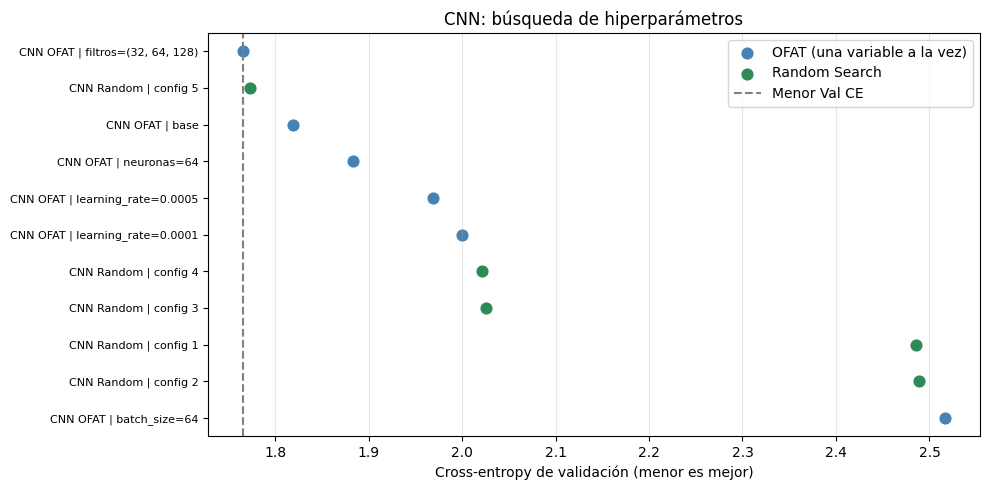

Hiperparámetros finales CNN: {'filtros': (32, 64, 128), 'neuronas': 128, 'capas_mlp': (128, 64), 'learning_rate': 0.001, 'batch_size': 32, 'dropout_conv': 0.25, 'dropout_dense': 0.5, 'l1': 1e-05, 'l2': 0.0001, 'patience': 5}


In [ ]:

HP_FINAL_CNN, resumen_cnn, registro_cnn = optimizar_modelo(
    "CNN", TECNICAS_SELECCIONADAS, HP_BASE, datos
)
print("Tabla O-A. Baseline y mejores opciones de cada método (CNN)")
display(resumen_cnn.round(4))
print("Tabla O-B. Configuraciones probadas (CNN)")
display(registro_cnn.sort_values("Val CE")[COLUMNAS_OPTIMIZACION].round(4))
graficar_optimizacion(registro_cnn, "CNN")
print("Hiperparámetros finales CNN:", HP_FINAL_CNN)

MLP: learning_rate = 0.0005 (Val CE 2.1519)
MLP: batch_size = 32 (Val CE 2.1519)
Tabla O-A. Baseline y mejores opciones de cada metodo (MLP)


,Configuración,Experimentos,Mejor Val CE,Val loss,Val accuracy,Val precision,Val recall,Val F1,Val ROC AUC,Hiperparámetros,Observaciones,Elegido
0,Baseline (partida),1,2.1976,2.1976,0.2586,0.2570,0.2638,0.2518,0.7385,"learning_rate=0.001, batch_size=32",punto de partida,
1,Mejor de OFAT (una variable a la vez),4,2.1519,2.1519,0.2691,0.2689,0.2690,0.2548,0.7546,"learning_rate=0.0005, batch_size=32",difiere de baseline,sí
2,Mejor de Random Search,5,2.1883,2.1883,0.2586,0.2726,0.2608,0.2553,0.7410,"learning_rate=0.00018416335322325736, batch_si...",difiere de baseline,no


Tabla O-B. Configuraciones probadas (MLP)


,Método,Experimento,LR,Batch,Dropout,L1,L2,Neuronas,Filtros,Val accuracy,Val precision,Val recall,Val F1,Val ROC AUC,Val CE,Val loss,Tiempo (s)
2,OFAT (una variable a la vez),MLP OFAT | learning_rate=0.0005,0.0005,32,None,None,None,None,None,0.2691,0.2689,0.2690,0.2548,0.7546,2.1519,2.1519,101.5657
6,Random Search,MLP Random | config 3,0.0002,64,None,None,None,None,None,0.2586,0.2726,0.2608,0.2553,0.7410,2.1883,2.1883,93.4128
4,Random Search,MLP Random | config 1,0.0001,64,None,None,None,None,None,0.2612,0.2511,0.2654,0.2466,0.7468,2.1932,2.1932,106.2451
0,OFAT (una variable a la vez),MLP OFAT | base,0.0010,32,None,None,None,None,None,0.2586,0.2570,0.2638,0.2518,0.7385,2.1976,2.1976,66.1718
7,Random Search,MLP Random | config 4,0.0001,32,None,None,None,None,None,0.2480,0.2401,0.2534,0.2370,0.7416,2.2073,2.2073,106.9230
5,Random Search,MLP Random | config 2,0.0003,64,None,None,None,None,None,0.2718,0.2717,0.2708,0.2393,0.7506,2.2181,2.2181,82.3467
1,OFAT (una variable a la vez),MLP OFAT | learning_rate=0.0001,0.0001,32,None,None,None,None,None,0.2401,0.2577,0.2529,0.2323,0.7473,2.2203,2.2203,98.6311
3,OFAT (una variable a la vez),MLP OFAT | batch_size=64,0.0005,64,None,None,None,None,None,0.2375,0.2693,0.2455,0.2237,0.7312,2.2526,2.2526,52.7519
8,Random Search,MLP Random | config 5,0.0002,32,None,None,None,None,None,0.2375,0.2473,0.2437,0.2208,0.7149,2.2676,2.2676,48.9106


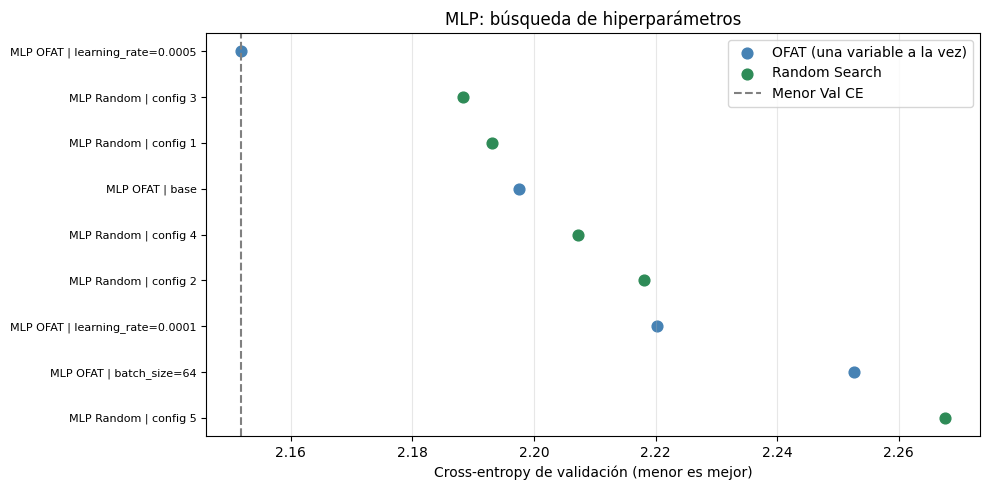

Hiperparametros finales MLP: {'filtros': (16, 32, 64), 'neuronas': 128, 'capas_mlp': (128, 64), 'learning_rate': 0.0005, 'batch_size': 32, 'dropout_conv': 0.25, 'dropout_dense': 0.5, 'l1': 1e-05, 'l2': 0.0001, 'patience': 5}
Variacion orientativa: 1.8189 vs 1.8189; diferencia absoluta=0.0000
CNN: OFAT=1.7659; Random Search=1.7736; diferencia absoluta=0.0077. 
MLP: OFAT=2.1519; Random Search=2.1883; diferencia absoluta=0.0364. 


In [ ]:

HP_FINAL_MLP, resumen_mlp, registro_mlp = optimizar_modelo(
    "MLP", TECNICAS_SELECCIONADAS, HP_BASE, datos
)
print("Tabla O-A. Baseline y mejores opciones de cada metodo (MLP)")
display(resumen_mlp.round(4))
print("Tabla O-B. Configuraciones probadas (MLP)")
display(registro_mlp.sort_values("Val CE")[COLUMNAS_OPTIMIZACION].round(4))
graficar_optimizacion(registro_mlp, "MLP")
print("Hiperparametros finales MLP:", HP_FINAL_MLP)

ce_combinacion_ref = (float(exp_combinacion["fila"]["Val CE"])
                      if exp_combinacion is not None and
                      tuple(TECNICAS_SELECCIONADAS) == tuple(
                          t.strip() for t in exp_combinacion["fila"]["Técnicas"].split(" + ")
                      ) else None)
ce_ofat_base = float(resumen_cnn.iloc[0]["Mejor Val CE"])
if ce_combinacion_ref is not None:
    print(f"Variacion orientativa: "
          f"{ce_combinacion_ref:.4f} vs {ce_ofat_base:.4f}; "
          f"diferencia absoluta={abs(ce_combinacion_ref-ce_ofat_base):.4f}")
else:
    print("No hubo una combinacion exactamente equivalente para comparar")
for nombre_arq, resumen in [("CNN", resumen_cnn), ("MLP", resumen_mlp)]:
    ofat = float(resumen[resumen["Configuración"].str.contains("OFAT")]["Mejor Val CE"].iloc[0])
    random_ = float(resumen[resumen["Configuración"].str.contains("Random")]["Mejor Val CE"].iloc[0])
    print(f"{nombre_arq}: OFAT={ofat:.4f}; Random Search={random_:.4f}; "
          f"diferencia absoluta={abs(ofat-random_):.4f}. ")


### 7.2 Resultados de la optimización e incertidumbre

En la CNN, OFAT obtuvo una Val CE de 1,7659, mientras que Random Search alcanzó 1,7736. La diferencia fue de 0,0077 a favor de OFAT.

Sin embargo, Random Search consiguió un F1 macro de validación de 0,4193, superior al 0,3920 de OFAT. Esto demuestra que la selección puede cambiar según la métrica priorizada. Nosotros mantuvimos la cross-entropy de validación como criterio principal.

En la MLP también ganó OFAT, con 2,1519 frente a 2,1883 de Random Search, una diferencia de 0,0364.

Aunque OFAT obtuvo la menor pérdida en ambas arquitecturas, las diferencias entre los métodos fueron pequeñas. No podemos asegurar que OFAT sea siempre superior sin repetir los experimentos con distintas semillas.

La configuración de partida de la CNN obtuvo la misma Val CE de 1,8189 en las secciones 6 y 7. Esta coincidencia no demuestra que el entrenamiento carezca de variabilidad; solamente muestra consistencia en esas ejecuciones.

Por lo tanto, seleccionamos OFAT porque obtuvo la menor Val CE entre las configuraciones probadas. La búsqueda se realizó con un presupuesto acotado y no garantiza haber encontrado los mejores hiperparámetros posibles.

**Comportamiento del batch 64.**

En la CNN, las tres configuraciones con batch 64 obtuvieron
accuracies de validación entre 9,2% y 11,9%, cercanas
al azar para 12 clases (8,3%).

En el ensayo OFAT, donde solo cambiamos el lote de
32 a 64, la accuracy bajó de 38,3% a 11,9%.
Esto muestra que el cambio de lote coincidió con una
caída importante del rendimiento en esa configuración.

El aumento del tamaño de lote estuvo acompañado de una caída importante del rendimiento. Aunque batch 64 realiza menos actualizaciones por época, no podemos asegurar que esta sea la única causa del resultado.

Por eso, mantuvimos batch 32, que obtuvo mejores
resultados en nuestros experimentos.

## 8. Entrenamiento final: Pipeline Integrado

Después de optimizar únicamente con validación, reutilizamos los hiperparámetros seleccionados para volver a entrenar las cuatro configuraciones (MLP base/final, CNN base/final). La función optimizar_modelo() se encarga de buscar los mejores hiperparámetros, mientras que main() organiza
el entrenamiento, evaluación y auditoría de cada modelo.

**Flujo de cada ejecución de main():** preparar datos (o reutilizarlos) → construir con regularización opcional → entrenar → evaluar curvas y métricas → auditar errores por raza y brillo → aplicar Grad-CAM (CNN) o saliencia por gradiente (MLP) → elaborar reporte → guardar modelo y configuración. El conjunto de prueba se consulta solo después de elegir técnicas e hiperparámetros y no se emplea para modificarlos retrospectivamente.

### 8.1 Métricas, auditoría y explicación

En esta etapa se definen las funciones para evaluar
el rendimiento de los modelos, generar las matrices de
confusión, revisar posibles sesgos y explicar algunas
predicciones mediante herramientas XAI.


In [ ]:
def calcular_metricas(y_true, y_pred, probs):
    """Metricas de clasificacion: accuracy, precision, recall y F1, y ROC-AUC"""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "roc_auc_ovr": roc_auc_score(y_true, probs, multi_class="ovr", average="macro"),
    }


def evaluar_metricas(modelo, x_test, y_test, class_names):
    """
    Evaluacion en el conjunto de prueba.

    Returns
    -------
    dict con metricas, matriz_confusion, classification_report_df, pred y probs.
    """
    probs = modelo.predict(x_test, verbose=0).astype("float64")
    pred = np.argmax(probs, axis=1)
    reporte = classification_report(y_test, pred, target_names=class_names, zero_division=0,
                                    output_dict=True)
    reporte.pop("accuracy", None)
    return {
        "metricas": calcular_metricas(y_test, pred, probs),
        "matriz_confusion": confusion_matrix(y_test, pred, labels=range(len(class_names))),
        "classification_report_df": pd.DataFrame(reporte).T,
        "pred": pred,
        "probs": probs,
    }


def capas_convolucionales(modelo):
    """Salidas de la ReLU de cada bloque convolucional"""
    return [capa for capa in modelo.layers if capa.name.startswith("ReLU_conv_")]



def generar_gradcam(modelo, img, clase_idx, capa_nombre):
    """
    Genera un mapa Grad-CAM usando la puntuación de
    la clase antes de softmax.
    """

    img_tensor = tf.convert_to_tensor(
        np.expand_dims(img, axis=0),
        dtype=tf.float32
    )

    capa_conv = modelo.get_layer(capa_nombre)
    capa_salida = modelo.get_layer("Salida")


    modelo_grad = keras.Model(
        inputs=modelo.inputs,
        outputs=[
            capa_conv.output,
            capa_salida.input
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, entrada_salida = modelo_grad(
            img_tensor, training=False
        )
        logits = tf.matmul(
            entrada_salida,
            capa_salida.kernel
        ) + capa_salida.bias

        puntuacion = logits[:, clase_idx]

    grads = tape.gradient(puntuacion, conv_outputs)

    if grads is None:
        raise ValueError(
            "No se pudieron calcular los gradientes"
        )
    pesos = tf.reduce_mean(grads, axis=(0, 1, 2))

    cam = tf.reduce_sum(
        conv_outputs[0] * pesos,
        axis=-1
    )

    cam = tf.maximum(cam, 0)

    maximo = float(tf.reduce_max(cam).numpy())

    if maximo <= 1e-8:
        print(
            f"Grad-CAM sin activaciones positivas "
            f"en {capa_nombre}."
        )
        return np.zeros(IMG_SIZE, dtype=np.float32)

    cam = cam / maximo

    cam = tf.image.resize(
        cam[..., tf.newaxis],
        IMG_SIZE
    )

    return cam.numpy()[..., 0]





def mapa_saliencia(modelo, img, clase_idx):
    """Saliencia por gradiente de la clase predicha respecto a los pixeles

    Se utilizan las puntuaciones previas a softmax para evitar la
    saturacion de probabilidad. El mapa muestra sensibilidad local,
    no una segmentacion ni una explicacion causal
    """
    capa_salida = modelo.get_layer("Salida")
    extractor = keras.Model(inputs=modelo.inputs, outputs=capa_salida.input)
    x = tf.convert_to_tensor(img[np.newaxis, ...], dtype=tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(x)
        caracteristicas = extractor(x, training=False)
        logits = tf.matmul(caracteristicas, capa_salida.kernel)
        if capa_salida.use_bias:
            logits = logits + capa_salida.bias
        puntuacion = logits[:, int(clase_idx)]

    gradientes = tape.gradient(puntuacion, x)
    if gradientes is None:
        raise ValueError("No se pudieron calcular los gradientes de entrada para la MLP")
    saliencia = tf.reduce_max(tf.abs(gradientes[0]), axis=-1)
    maximo = float(tf.reduce_max(saliencia).numpy())
    if maximo <= 1e-8:
        return np.zeros(img.shape[:2], dtype=np.float32)
    return (saliencia / maximo).numpy()


def explicar_modelo(modelo, tipo_modelo, x_test, y_test, class_names, nombre, indice_imagen=None):
    """
    Explicación visual de una prediccion

    CNN: Grad-CAM sobre la última activación convolucional
    MLP: saliencia por gradiente de entrada, calculada antes de softmax
    Devuelve un resumen que se incorpora al reporte
    """
    probs = modelo.predict(x_test, verbose=0)
    pred = np.argmax(probs, axis=1)
    if indice_imagen is None:
        aciertos = np.where(pred == y_test)[0]
        indice_imagen = int(aciertos[0]) if len(aciertos) else 0
    img = x_test[indice_imagen]
    real, predicha = int(y_test[indice_imagen]), int(pred[indice_imagen])
    prob = float(probs[indice_imagen, predicha])
    print(f"Imagen {indice_imagen}: real = {class_names[real]} | predicha = {class_names[predicha]} "
          f"| probabilidad = {prob:.2f}")
    resumen = {"indice": indice_imagen, "real": class_names[real],
               "predicha": class_names[predicha], "probabilidad": prob}
    if tipo_modelo == "CNN":
        capa = capas_convolucionales(modelo)[-1].name
        mapa = generar_gradcam(modelo, img, predicha, capa)
        herramienta = "Grad-CAM"
        titulo = f"Grad-CAM ({capa})"
    elif tipo_modelo == "MLP":
        mapa = mapa_saliencia(modelo, img, predicha)
        herramienta = "Saliencia por gradiente"
        titulo = "Saliencia (gradiente de entrada)"
    else:
        raise ValueError("tipo_modelo debe ser 'CNN' o 'MLP'")

    fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
    axs[0].imshow(img)
    axs[0].set_title("Imagen original")
    axs[1].imshow(mapa, cmap="jet")
    axs[1].set_title(titulo)
    axs[2].imshow(img)
    axs[2].imshow(mapa, cmap="jet", alpha=0.5)
    axs[2].set_title("Superposicion")
    for ax in axs:
        ax.axis("off")
    plt.suptitle(f"{nombre}: explicacion visual con {herramienta}", fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    guardar(f"xai_{slug(nombre)}")
    plt.show()
    return {"herramienta": herramienta, **resumen}


def generar_reporte(nombre_modelo, tipo_modelo, modelo, metricas, classification_report_df,
                    learning_curves, explanation_result, entrenamiento):
    """
    Reporte de una configuración: una fila con las metricas, el diagnostico de las curvas,
    la explicacion y el costo de entrenamiento. Las filas de todos los modelos se concatenan para comparar
    """
    razas = classification_report_df.drop(["accuracy", "macro avg", "weighted avg"], errors="ignore")
    peor = razas["f1-score"].idxmin()
    fila = {
        "Modelo": nombre_modelo,
        "Arquitectura": tipo_modelo,
        "Parámetros": modelo.count_params(),
        "Épocas": entrenamiento["epocas"],
        "Mejor época": entrenamiento["mejor_epoca"],
        "Accuracy": metricas["accuracy"],
        "Precision": metricas["precision_macro"],
        "Recall": metricas["recall_macro"],
        "F1": metricas["f1_macro"],
        "ROC-AUC": metricas["roc_auc_ovr"],
        "Train accuracy (inferencia)": learning_curves["train_acc_inferencia"],
        "Val accuracy (inferencia)": learning_curves["val_acc_inferencia"],
        "Brecha train-val": learning_curves["brecha"],
        "Brecha train-prueba": learning_curves["train_acc_inferencia"] - metricas["accuracy"],
        "Diagnóstico curvas": learning_curves["diagnostico"],
        "Raza con menor F1": f"{peor} ({razas.loc[peor, 'f1-score']:.2f})",
        "XAI": explanation_result["herramienta"],
        "Clase real (XAI)": explanation_result.get("real", "n/a"),
        "Clase predicha (XAI)": explanation_result.get("predicha", "n/a"),
        "Probabilidad (XAI)": explanation_result.get("probabilidad", np.nan),
        "Tiempo entrenamiento (s)": entrenamiento["tiempo_s"],
        "Tiempo/época (s)": entrenamiento["tiempo_s"] / entrenamiento["epocas"],
    }
    return pd.DataFrame([fila])


def guardar_modelo_final(nombre, modelo, cfg):
    """Guarda el modelo final"""
    base = slug(nombre)
    modelo.save(os.path.join(MODELS_DIR, f"{base}.keras"))
    with open(os.path.join(MODELS_DIR, f"{base}_config.json"), "w", encoding="utf-8") as f:
        json.dump({"nombre": nombre, **cfg}, f, indent=2, ensure_ascii=False, default=_a_json)

def auditar_brillo_rendimiento(nombre, x_test, y_test, pred, mostrar=False):
    """Accuracy en tres grupos de brillo de igual tamaño; asociación, no causalidad."""
    brillo = x_test.mean(axis=(1, 2, 3))
    grupo = pd.qcut(pd.Series(brillo).rank(method="first"), 3,
                    labels=["Oscuras", "Medias", "Claras"])
    tabla = (pd.DataFrame({"Grupo": grupo, "Acierto": (pred == y_test).astype(int)})
             .groupby("Grupo", observed=True)["Acierto"]
             .agg(["mean", "count"])
             .rename(columns={"mean": "Accuracy", "count": "Imagenes"}))
    if mostrar:
        print(f"--- {nombre}: accuracy según el brillo ---")
        display(tabla.round(3))
    return tabla


def auditar_modelo(nombre, evaluacion, datos_main, class_names):
    """Resume errores por raza y brillo sin cambiar parametros ni entrenar con prueba"""
    cm = evaluacion["matriz_confusion"]
    reporte = evaluacion["classification_report_df"]
    por_raza = pd.DataFrame({
        "Raza": class_names,
        "Casos reales": cm.sum(axis=1),
        "Predicciones": cm.sum(axis=0),
        "Aciertos": np.diag(cm),
        "F1": [float(reporte.loc[raza, "f1-score"]) for raza in class_names],
    })
    por_raza["Predicciones de más"] = por_raza["Predicciones"] - por_raza["Casos reales"]
    por_brillo = auditar_brillo_rendimiento(nombre, datos_main["X_test"],
                                           datos_main["y_test"], evaluacion["pred"])
    return {"por_raza": por_raza, "por_brillo": por_brillo}


### 8.2 Función main() — coordinación del Pipeline

La función main() sigue la estructura modular: carga y analiza los datos cuando no recibe los arrays preparados, construye y entrena la red, calcula métricas, revisa curvas, realiza la auditoría, aplica XAI a ambas arquitecturas (Grad-CAM en CNN y saliencia en MLP) y guarda el reporte y el modelo. En esta evaluación reutilizamos normalmente los arrays creados en la sección 2 para evitar duplicar el preprocesamiento.

La búsqueda de hiperparámetros se conserva en optimizar_modelo() y se ejecuta antes, en la sección 7. main() recibe los hiperparámetros elegidos; no los decide mirando el conjunto de prueba. Esto mantiene independientes las funciones y permite volver a usar el Pipeline para ambas arquitecturas.


In [ ]:
def main(nombre, tipo_modelo, regularizacion=False, tecnicas=(), hp=None, epochs=EPOCHS,
         datos_preparados=None, class_names_preparadas=None):
    """
    Coordina el Pipeline completo:

    Etapas: cargar/analizar/preprocesar si no hay arrays; construir con regularizacion
    opcional; entrenar; evaluar curvas y métricas; auditar raza y brillo; aplicar XAI
    (Grad-CAM en CNN, saliencia en MLP); generar reporte y guardar el modelo.
    se realiza antes con optimizar_modelo(), utilizando validacion, y entrega hp.
    No se seleccionan hiperparametros usando los resultados de prueba.

    Returns
    -------
    dict con modelo, resultados, auditoria y datos de la ejecucion.
    """
    if hp is None:
        raise ValueError("Debes pasar hp explicitamente (por ejemplo hp=HP_BASE).")
    hp = dict(hp)
    tecnicas = tuple(tecnicas) if regularizacion else ()
    if tipo_modelo not in ("CNN", "MLP"):
        raise ValueError("tipo_modelo debe ser 'CNN' o 'MLP'")
    print("=" * 80)
    print(f"PIPELINE | {nombre} | arquitectura={tipo_modelo} | regularizacion={regularizacion}")
    print(f"Técnicas: {list(tecnicas) or 'ninguna'} | épocas máx.={epochs} | batch={hp['batch_size']}")
    print("=" * 80)


    if datos_preparados is not None:
        if class_names_preparadas is None:
            raise ValueError("Faltan class_names_preparadas")
        datos_main, nombres = datos_preparados, class_names_preparadas
    else:
        descargar_dataset()
        particionar_dataset()
        train_ds, val_ds, test_ds, nombres = cargar_datos(batch_size=hp["batch_size"])
        analizar_dataset(train_ds, nombres, mostrar=False)
        verificar_particion(train_ds, val_ds)
        datos_main = preprocesar(train_ds, val_ds, test_ds)

    if len(nombres) != datos_main["num_clases"]:
        raise ValueError("La cantidad de clases no coincide con las etiquetas")


    modelo = construir_modelo(tipo_modelo, regularizacion, tecnicas, hp,
                              datos_main["num_clases"])

    modelo, history, res = entrenar(modelo, datos_main["X_train"], datos_main["y_train"],
                                   datos_main["X_val"], datos_main["y_val"],
                                   regularizacion, tecnicas, epochs=epochs,
                                   batch_size=hp["batch_size"], patience=hp["patience"])
    print(f"Épocas: {res['epocas']} | época conservada: {res['mejor_epoca']} "
          f"| tiempo: {res['tiempo_s']:.1f} s")


    _, acc_train_inf = modelo.evaluate(datos_main["X_train"], datos_main["y_train"], verbose=0)
    _, acc_val_inf = modelo.evaluate(datos_main["X_val"], datos_main["y_val"], verbose=0)
    probs_val = modelo.predict(datos_main["X_val"], verbose=0)
    res["val_ce"] = float(log_loss(datos_main["y_val"], probs_val,
                                   labels=np.arange(datos_main["num_clases"])))
    diagnostico = evaluar_aprendizaje(history, nombre, indice=res["mejor_epoca"] - 1,
                                      train_inf=float(acc_train_inf),
                                      val_inf=float(acc_val_inf))


    evaluacion = evaluar_metricas(modelo, datos_main["X_test"],
                                  datos_main["y_test"], nombres)


    auditoria = auditar_modelo(nombre, evaluacion, datos_main, nombres)
    explicacion = explicar_modelo(modelo, tipo_modelo, datos_main["X_test"],
                                  datos_main["y_test"], nombres, nombre)


    reporte = generar_reporte(nombre, tipo_modelo, modelo, evaluacion["metricas"],
                              evaluacion["classification_report_df"],
                              diagnostico, explicacion, res)
    cfg = {"tipo_modelo": tipo_modelo, "regularizacion": regularizacion,
           "tecnicas": list(tecnicas), "hp": hp, "epochs": epochs, "semilla": SEED}
    guardar_modelo_final(nombre, modelo, cfg)
    return {"nombre": nombre, "modelo": modelo, "history": history,
            "res": res, "reporte": reporte, "evaluacion": evaluacion,
            "diagnostico": diagnostico, "explicacion": explicacion,
            "auditoria": auditoria}


### 8.3 Comparación de cuatro configuraciones

Volvemos a entrenar MLP base, MLP final, CNN base y CNN final para comparar su desempeño en condiciones conocidas y con el mismo conjunto de prueba. Los modelos finales incorporan las técnicas y los hiperparámetros elegidos con validación. El número de épocas **puede variar** si se activa EarlyStopping; por eso se registran tiempos totales y tiempos por época.

Estos cuatro modelos se construyen desde cero en esta ejecución, no se descargan ya entrenados. Las auditorías quedan almacenadas dentro de resultados y se muestran con detalle en la sección 9.


PIPELINE | MLP base | arquitectura=MLP | regularizacion=False
Técnicas: ninguna | épocas máx.=30 | batch=32
Épocas: 30 | época conservada: 30 | tiempo: 37.0 s


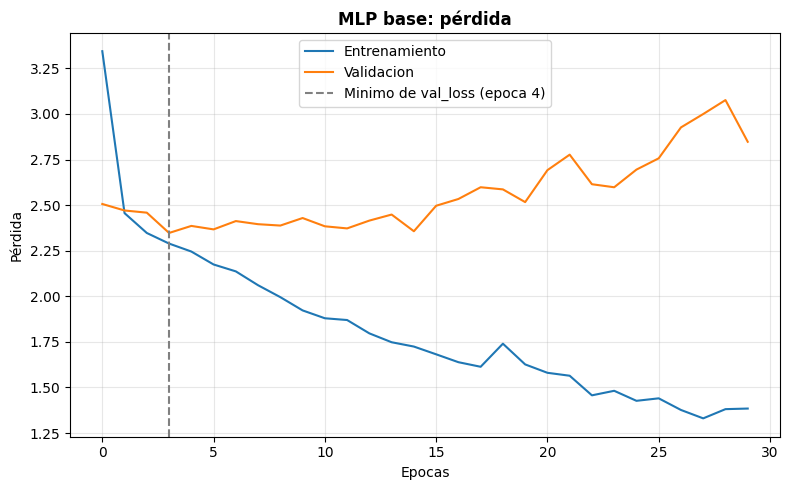

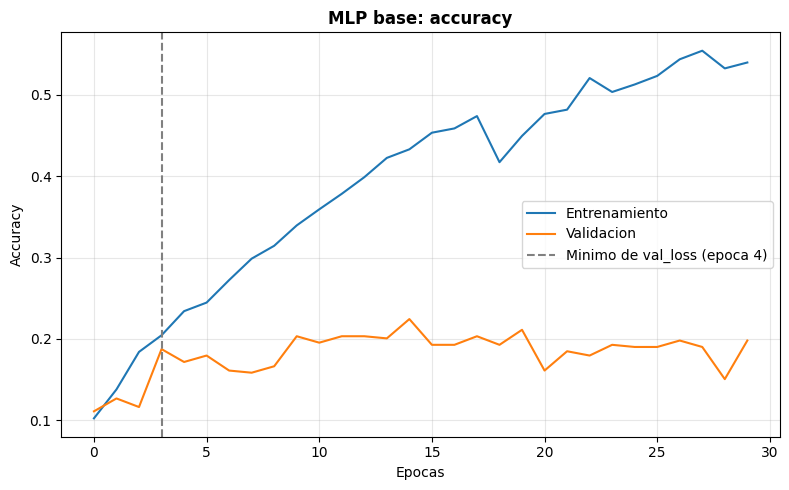

Época evaluada: 30 (mínimo de val_loss en la época 4)
Accuracy registrada en fit: train=0.540, val=0.198
Accuracy en inferencia: train=0.528, val=0.198; brecha=0.330
Diagnóstico: brecha notable train-val: revisar sobreajuste
Imagen 1: real = Abyssinian | predicha = Abyssinian | probabilidad = 0.40


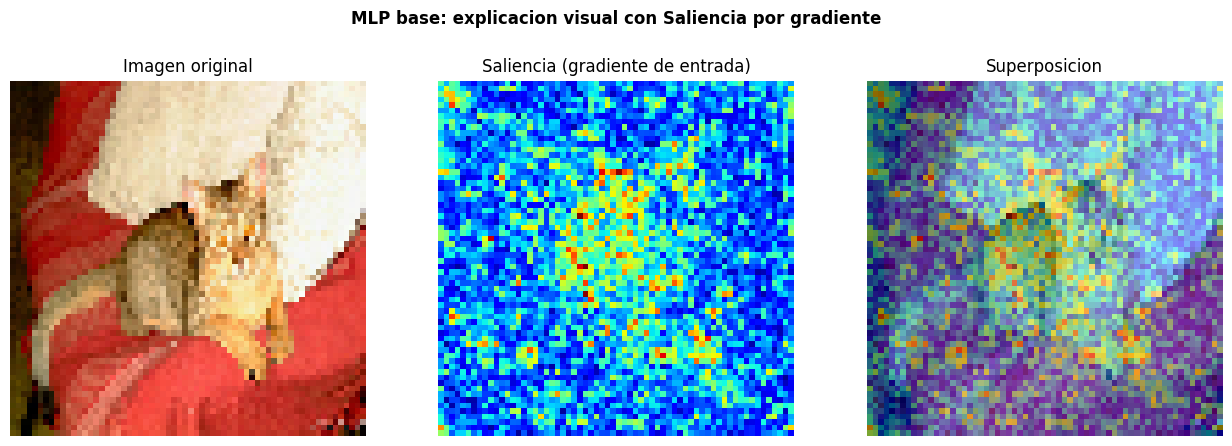

PIPELINE | MLP final | arquitectura=MLP | regularizacion=True
Técnicas: ['EarlyStopping', 'Data Augmentation', 'Batch Normalization'] | épocas máx.=30 | batch=32
Épocas: 24 | época conservada: 19 | tiempo: 108.1 s


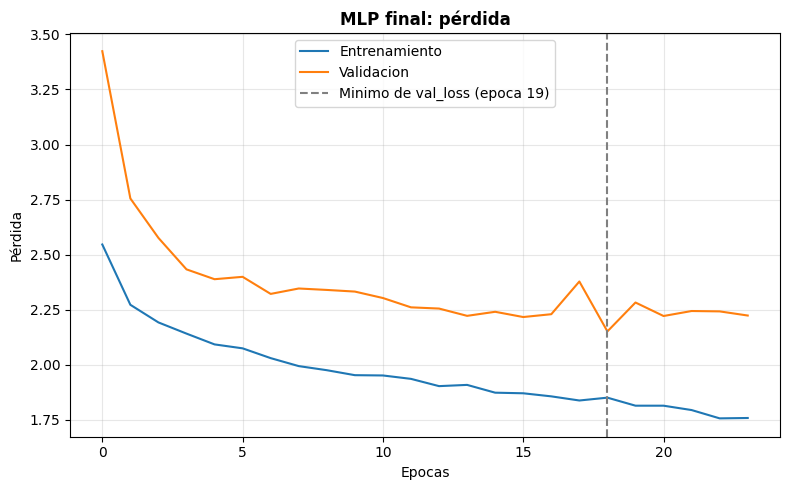

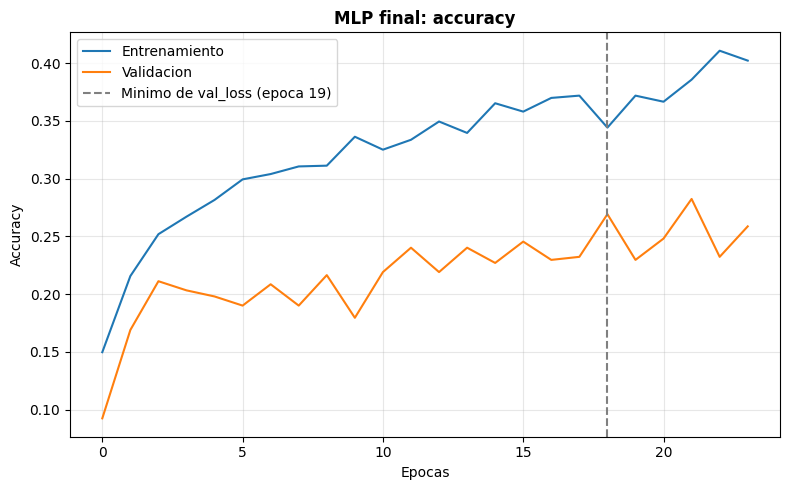

Época evaluada: 19 (mínimo de val_loss en la época 19)
Accuracy registrada en fit: train=0.344, val=0.269
Accuracy en inferencia: train=0.410, val=0.269; brecha=0.141
Diagnóstico: brecha moderada train-val: revisar sobreajuste
Imagen 3: real = Abyssinian | predicha = Abyssinian | probabilidad = 0.49


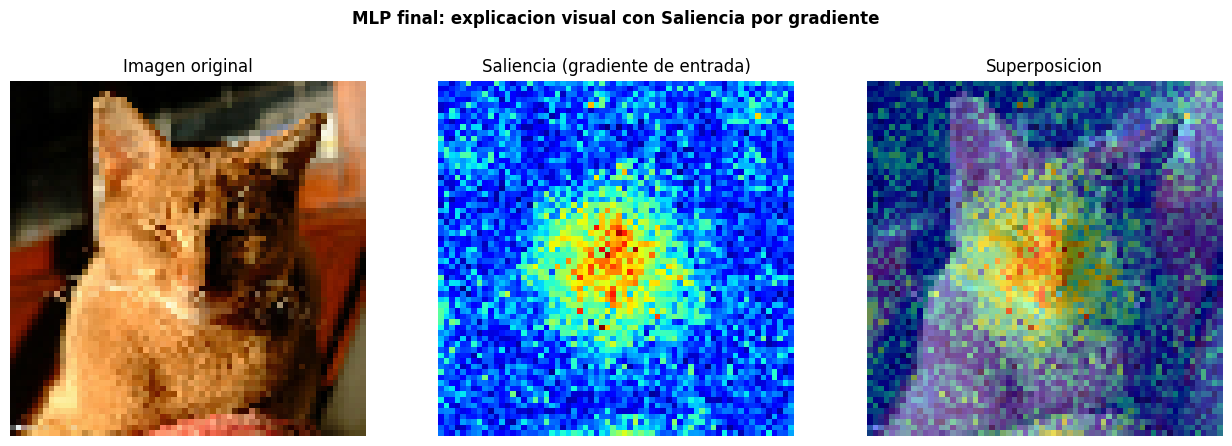

PIPELINE | CNN base | arquitectura=CNN | regularizacion=False
Técnicas: ninguna | épocas máx.=30 | batch=32
Épocas: 30 | época conservada: 30 | tiempo: 203.2 s


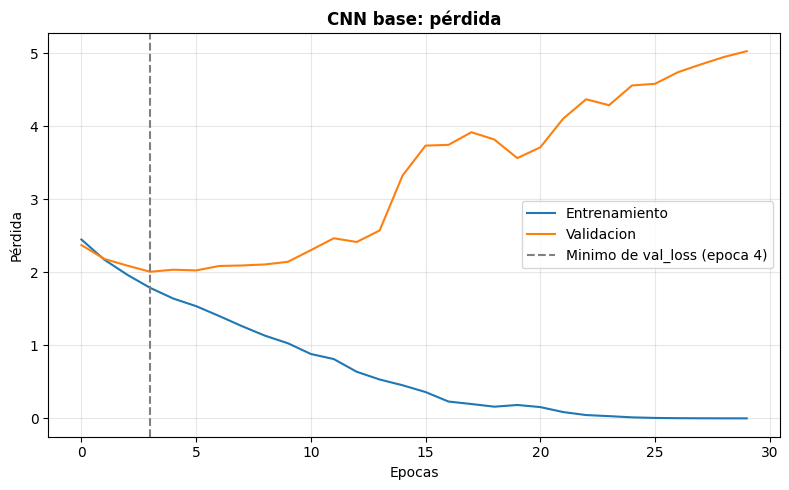

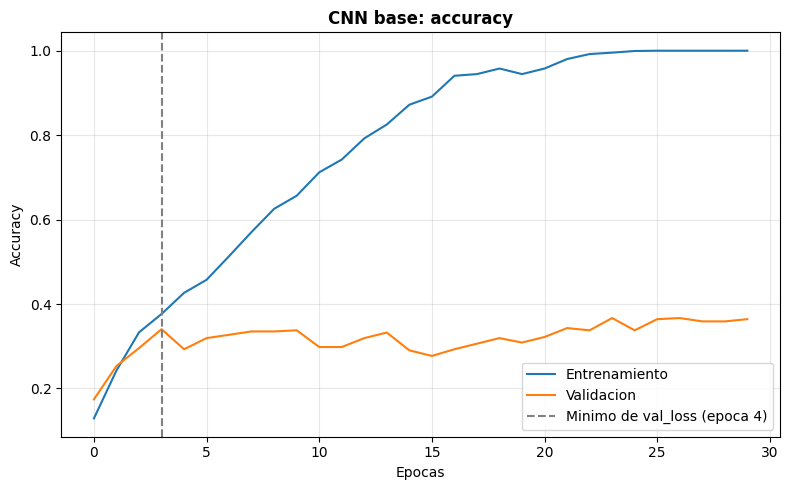

Época evaluada: 30 (mínimo de val_loss en la época 4)
Accuracy registrada en fit: train=1.000, val=0.364
Accuracy en inferencia: train=1.000, val=0.364; brecha=0.636
Diagnóstico: brecha notable train-val: revisar sobreajuste
Imagen 1: real = Abyssinian | predicha = Abyssinian | probabilidad = 1.00


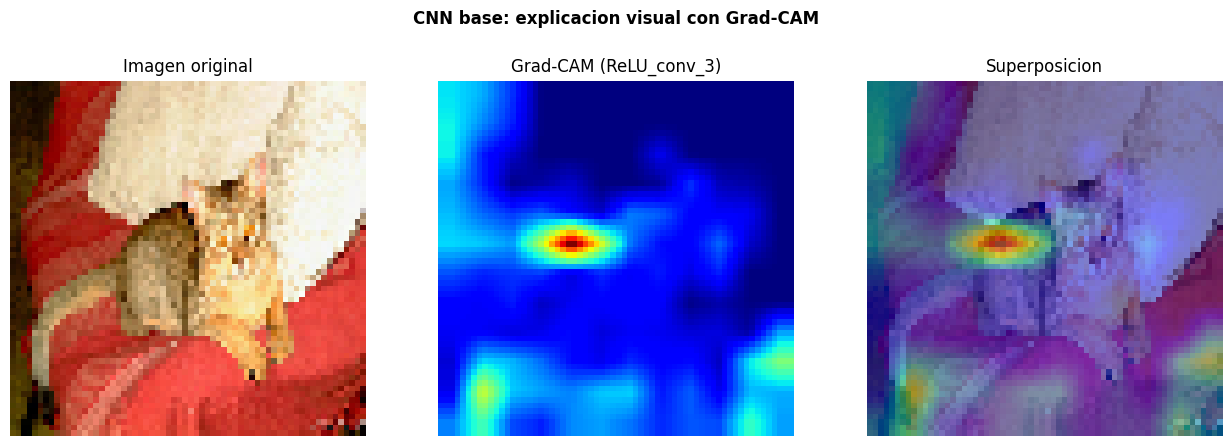

PIPELINE | CNN final | arquitectura=CNN | regularizacion=True
Técnicas: ['EarlyStopping', 'Data Augmentation', 'Batch Normalization'] | épocas máx.=30 | batch=32
Épocas: 14 | época conservada: 9 | tiempo: 298.1 s


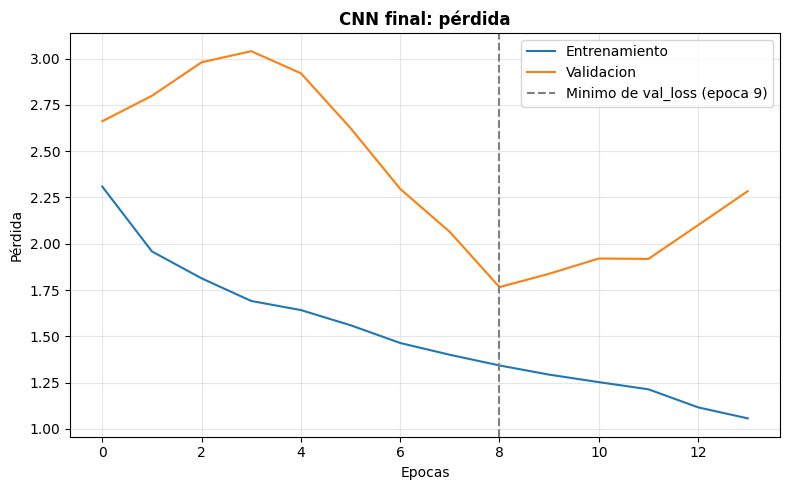

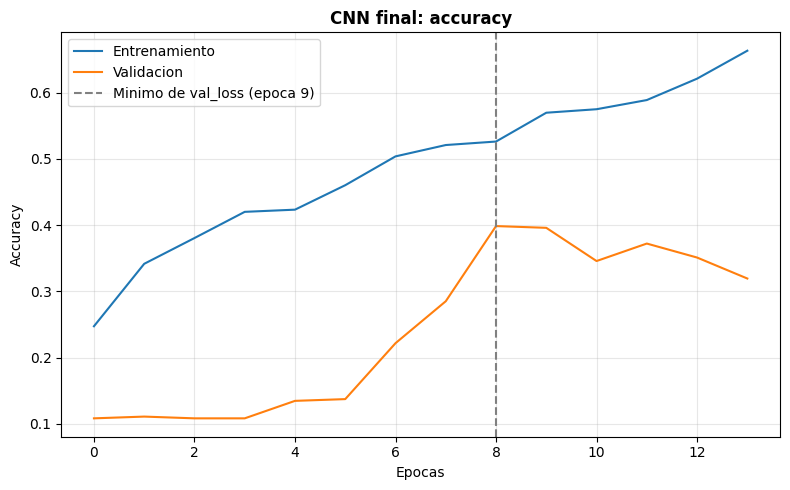

Época evaluada: 9 (mínimo de val_loss en la época 9)
Accuracy registrada en fit: train=0.526, val=0.398
Accuracy en inferencia: train=0.574, val=0.398; brecha=0.176
Diagnóstico: brecha notable train-val: revisar sobreajuste
Imagen 3: real = Abyssinian | predicha = Abyssinian | probabilidad = 0.40


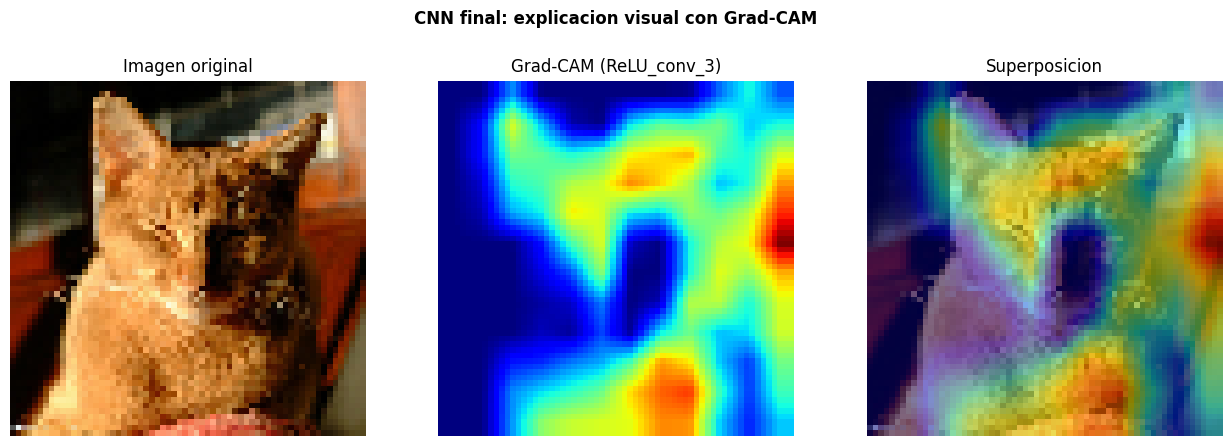

Configuraciones entrenadas: MLP base, MLP final, CNN base, CNN final


In [ ]:

resultados = {
    "MLP base": main("MLP base", "MLP", regularizacion=False, tecnicas=(), hp=HP_BASE, datos_preparados=datos, class_names_preparadas=class_names),
    "MLP final": main("MLP final", "MLP", regularizacion=True, tecnicas=TECNICAS_SELECCIONADAS, hp=HP_FINAL_MLP, datos_preparados=datos, class_names_preparadas=class_names),
    "CNN base": main("CNN base", "CNN", regularizacion=False, tecnicas=(), hp=HP_BASE, datos_preparados=datos, class_names_preparadas=class_names),
    "CNN final": main("CNN final", "CNN", regularizacion=True, tecnicas=TECNICAS_SELECCIONADAS, hp=HP_FINAL_CNN, datos_preparados=datos, class_names_preparadas=class_names),
}

reporte_comparativo = (
    pd.concat(
        [r["reporte"] for r in resultados.values()],
        ignore_index=True
    ).set_index("Modelo")
)

print("Configuraciones entrenadas:", ", ".join(resultados))


In [ ]:
print("=== ARQUITECTURA CNN FINAL ===")
resultados["CNN final"]["modelo"].summary()

print("\n=== ARQUITECTURA MLP FINAL ===")
resultados["MLP final"]["modelo"].summary()

=== ARQUITECTURA CNN FINAL ===


Model: "CNN_Gatos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_datos (Sequential)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_1 (Conv2D)          │ (None, 62, 62, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_conv_1                │ (None, 62, 62, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_conv_1 (Activation)        │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_1 (MaxPooling2D)        │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_2 (Conv2D)          │ (None, 29, 29, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_conv_2                │ (None, 29, 29, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_conv_2 (Activation)        │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_2 (MaxPooling2D)        │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolucion_3 (Conv2D)          │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_conv_3                │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_conv_3 (Activation)        │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pooling_3 (MaxPooling2D)        │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Aplanado (Flatten)              │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Densa_1 (Dense)                 │ (None, 128)            │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_densa_1               │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ReLU_densa_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida (Dense)                  │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,056,006 (7.84 MB)

 Trainable params: 685,100 (2.61 MB)

 Non-trainable params: 704 (2.75 KB)

... (4 outputs left out)

 Total params: 4,747,046 (18.11 MB)

 Trainable params: 1,582,220 (6.04 MB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 3,164,442 (12.07 MB)

## 9. Evaluación y auditoría

Los modelos finales se evalúan mediante accuracy, precisión, recall y F1 macro, F1 ponderado, ROC-AUC multiclase (one-vs-rest), matrices de confusión y métricas por raza. **F1 macro** da el mismo peso a cada clase. ROC-AUC analiza la discriminación de cada raza frente a las restantes y puede ser alto aunque la predicción más probable sea incorrecta.

La auditoría considera el balance por raza y la diferencia de accuracy entre grupos de brillo. Estos grupos son un **indicador aproximado** de las condiciones de captura; no identifican por sí solos la causa de los errores ni un sesgo hacia grupos humanos. Grad-CAM y la saliencia por gradiente permiten inspeccionar algunos aspectos de las predicciones de CNN y MLP, respectivamente, pero no demuestran causalidad.


In [ ]:
X_test, y_test = datos["X_test"], datos["y_test"]
ev_cnn = resultados["CNN final"]["evaluacion"]
ev_mlp = resultados["MLP final"]["evaluacion"]
pred_cnn, probs_cnn = ev_cnn["pred"], ev_cnn["probs"]
pred_mlp, probs_mlp = ev_mlp["pred"], ev_mlp["probs"]

tabla_metricas = pd.DataFrame({"MLP final": ev_mlp["metricas"], "CNN final": ev_cnn["metricas"]}).T
print("Metricas en el conjunto de prueba (modelos finales):")
display(tabla_metricas.round(3))

for nombre, ev in [("CNN final", ev_cnn), ("MLP final", ev_mlp)]:
    print(f"\n=== Reporte de clasificación por raza: {nombre} ===")
    display(ev["classification_report_df"].round(3))

Metricas en el conjunto de prueba (modelos finales):


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr
MLP final,0.293,0.290,0.295,0.279,0.277,0.763
CNN final,0.398,0.428,0.401,0.390,0.387,0.859



=== Reporte de clasificación por raza: CNN final ===


,precision,recall,f1-score,support
Abyssinian,0.355,0.275,0.310,40.0
Bengal,0.500,0.200,0.286,40.0
Birman,0.306,0.475,0.373,40.0
Bombay,0.769,0.811,0.789,37.0
British_Shorthair,0.341,0.350,0.346,40.0
Egyptian_Mau,0.432,0.421,0.427,38.0
Maine_Coon,0.429,0.225,0.295,40.0
Persian,0.295,0.575,0.390,40.0
Ragdoll,0.373,0.475,0.418,40.0
Russian_Blue,0.373,0.550,0.444,40.0



=== Reporte de clasificación por raza: MLP final ===


,precision,recall,f1-score,support
Abyssinian,0.262,0.275,0.268,40.0
Bengal,0.324,0.275,0.297,40.0
Birman,0.175,0.275,0.214,40.0
Bombay,0.537,0.784,0.637,37.0
British_Shorthair,0.205,0.200,0.203,40.0
Egyptian_Mau,0.321,0.237,0.273,38.0
Maine_Coon,0.333,0.150,0.207,40.0
Persian,0.367,0.275,0.314,40.0
Ragdoll,0.274,0.500,0.354,40.0
Russian_Blue,0.268,0.375,0.312,40.0


### 9.1 Matrices de confusión

En cada matriz, las filas corresponden a las clases reales y las columnas a las predicciones. La diagonal muestra los aciertos; los valores fuera de ella identifican pares de razas que se confunden. Analizamos esos errores junto con el reporte de F1 por clase, para no quedarnos solo con accuracy global.


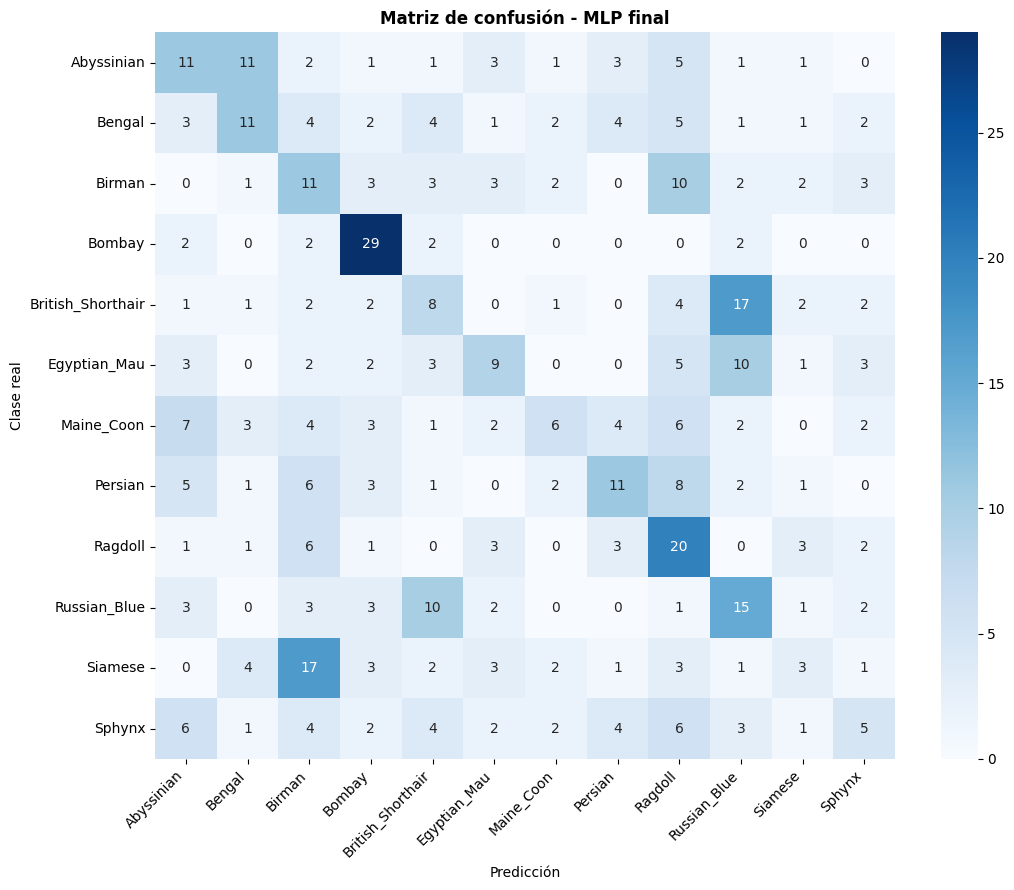

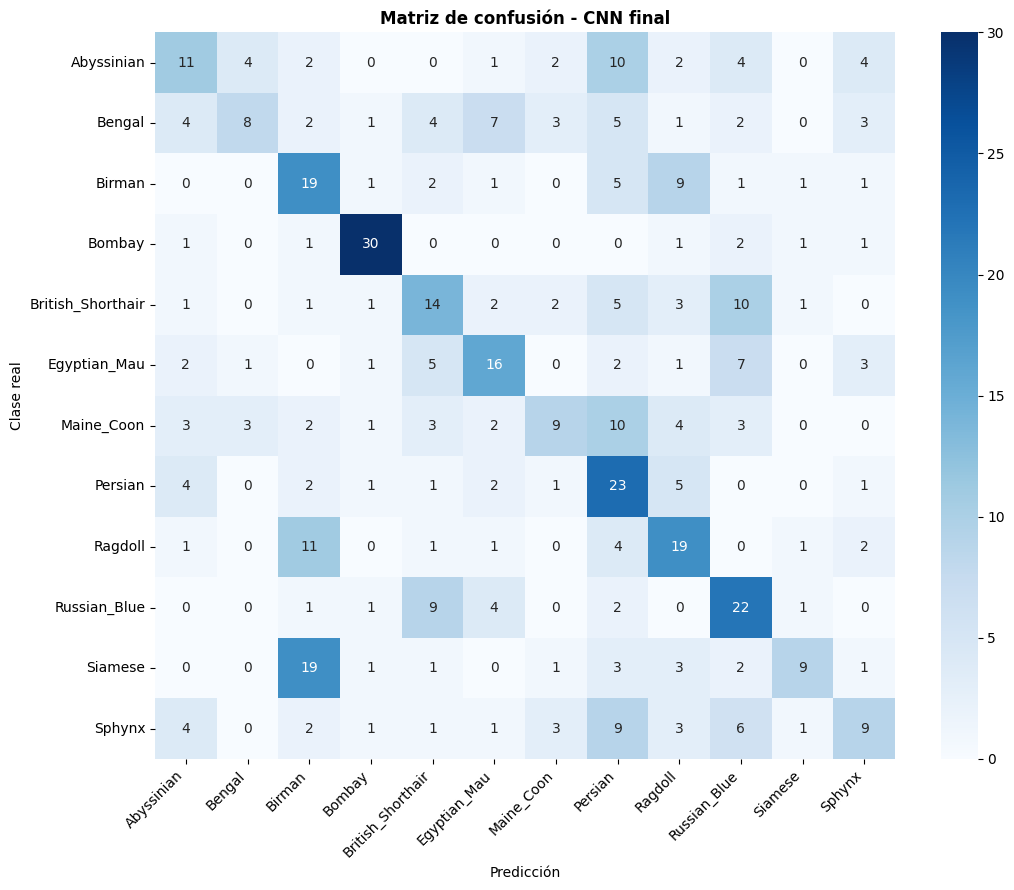

In [ ]:
def graficar_matriz_confusion(cm, nombre, class_names, nombre_fig):
    """Matriz de confusion de un modelo como mapa de calor. Una figura por modelo."""
    plt.figure(figsize=(11, 9))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Matriz de confusión - {nombre}", fontweight="bold")
    plt.xlabel("Predicción")
    plt.ylabel("Clase real")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    guardar(nombre_fig)
    plt.show()


graficar_matriz_confusion(ev_mlp["matriz_confusion"], "MLP final", class_names, "05a_matriz_confusion_mlp_final")
graficar_matriz_confusion(ev_cnn["matriz_confusion"], "CNN final", class_names, "05b_matriz_confusion_cnn_final")


**Lectura de resultados por raza.** Las matrices y el reporte de la sección anterior permiten identificar en qué razas falla cada modelo. Una accuracy general más alta no implica que todas las razas tengan mejor F1. Más adelante utilizamos el F1 bajo y la sobrepredicción de clases para proponer medidas concretas, sin atribuir los errores a una única causa.


### 9.2 Explicabilidad: Grad-CAM en CNN

Usamos Grad-CAM sobre la última activación convolucional de la CNN para revisar tres aciertos, tres errores y un ejemplo comparado entre CNN base y final. También calculamos saliencia por gradiente de entrada para la MLP, utilizando la puntuación previa a softmax de la clase predicha.

Para comparar visualmente ambos modelos se muestra la misma imagen de prueba con la CNN y la MLP. Los mapas se guardan dentro de images/Evaluacion_3/.

Los colores más intensos indican regiones relevantes según cada método. Grad-CAM usa activaciones convolucionales y produce mapas más gruesos; la saliencia de la MLP muestra sensibilidad de los píxeles de entrada y puede ser ruidosa. No son valores numéricos comparables ni segmentaciones exactas del gato. Si aparecen activaciones sobre el fondo, eso motiva pruebas futuras cambiando el contexto, sin ajustar los modelos a partir de estas imágenes de prueba.


Clases seleccionadas: ['Abyssinian', 'Bengal', 'Birman', 'Abyssinian', 'Bengal', 'Birman']


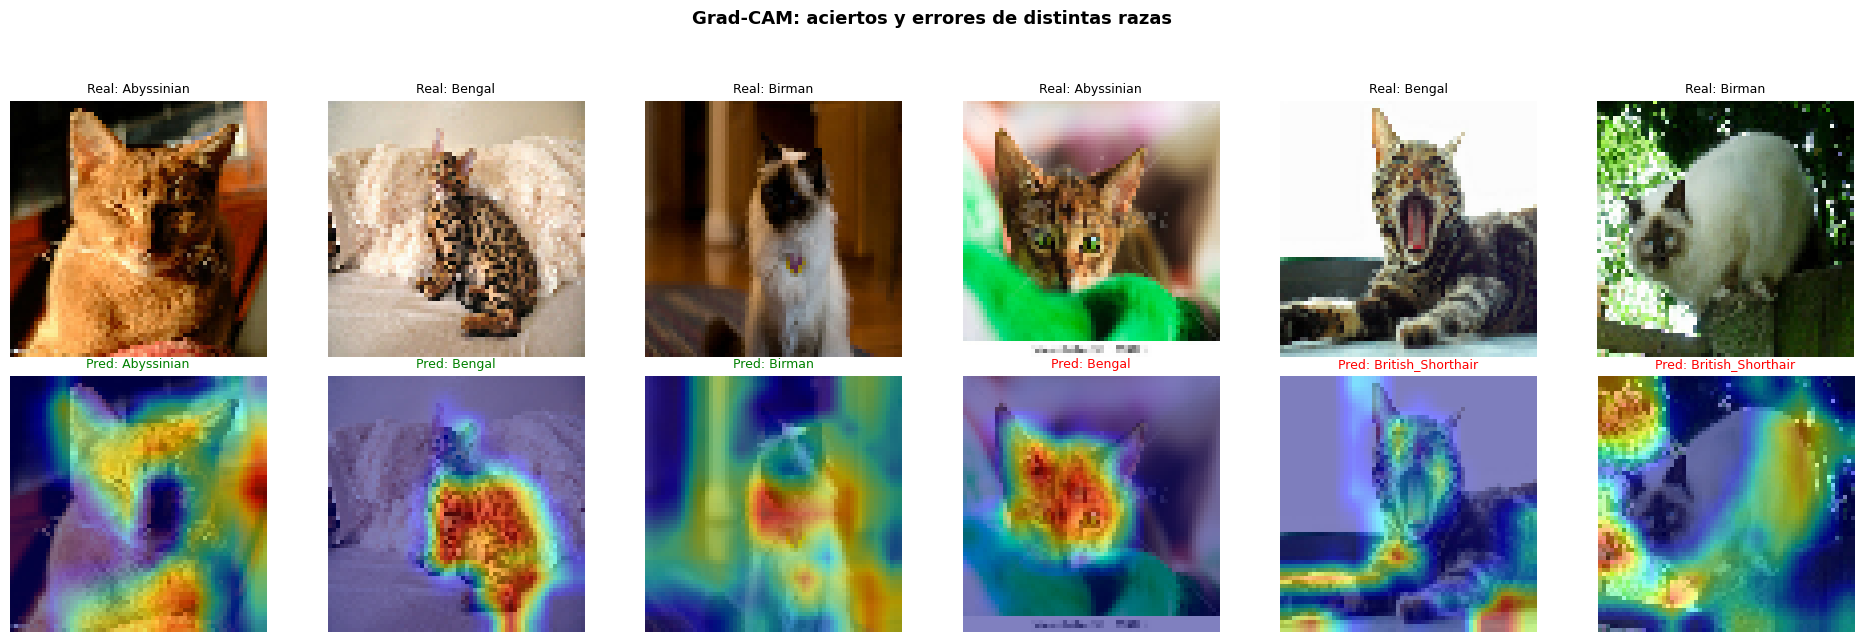

In [ ]:
def mostrar_gradcam_aciertos_errores(modelo, X, y, pred, class_names, capa_nombre):
    """Grad-CAM de 3 aciertos y 3 errores: una fila con la imagen y otra con el mapa superpuesto."""
    def elegir_diversas(indices, n=3):
        seleccion, razas_vistas = [], set()
        for idx in indices:
            clase = int(y[idx])
            if clase not in razas_vistas:
                seleccion.append(int(idx))
                razas_vistas.add(clase)
            if len(seleccion) == n:
                return seleccion
        for idx in indices:
            if int(idx) not in seleccion:
                seleccion.append(int(idx))
            if len(seleccion) == n:
                break
        return seleccion

    sel_ok = elegir_diversas(np.where(pred == y)[0])
    sel_err = elegir_diversas(np.where(pred != y)[0])
    muestras = sel_ok + sel_err
    if not muestras:
        print("No se encontraron muestras para Grad-CAM")
        return
    fig, axs = plt.subplots(2, len(muestras), figsize=(3.2 * len(muestras), 6.5), squeeze=False)
    print("Clases seleccionadas:", [class_names[int(y[i])] for i in muestras])
    for col, idx in enumerate(muestras):
        cam = generar_gradcam(modelo, X[idx], int(pred[idx]), capa_nombre)
        ok = pred[idx] == y[idx]
        axs[0, col].imshow(X[idx])
        axs[0, col].set_title(f"Real: {class_names[y[idx]]}", fontsize=9)
        axs[0, col].axis("off")
        axs[1, col].imshow(X[idx])
        axs[1, col].imshow(cam, cmap="jet", alpha=0.5)
        axs[1, col].set_title(f"Pred: {class_names[pred[idx]]}", fontsize=9, color="green" if ok else "red")
        axs[1, col].axis("off")
    plt.suptitle("Grad-CAM: aciertos y errores de distintas razas", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    guardar("06_gradcam_aciertos_vs_errores")
    plt.show()


capa_cnn = capas_convolucionales(resultados["CNN final"]["modelo"])[-1].name
mostrar_gradcam_aciertos_errores(resultados["CNN final"]["modelo"], X_test, y_test, pred_cnn,
                                 class_names, capa_cnn)

Imagen 3: real = Abyssinian | predicha = Maine_Coon | probabilidad = 1.00


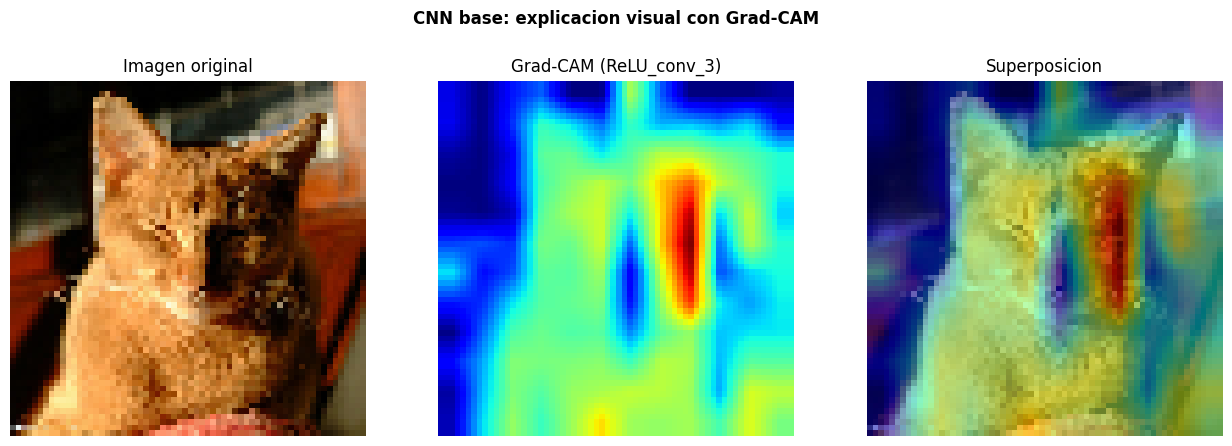

Imagen 3: real = Abyssinian | predicha = Abyssinian | probabilidad = 0.40


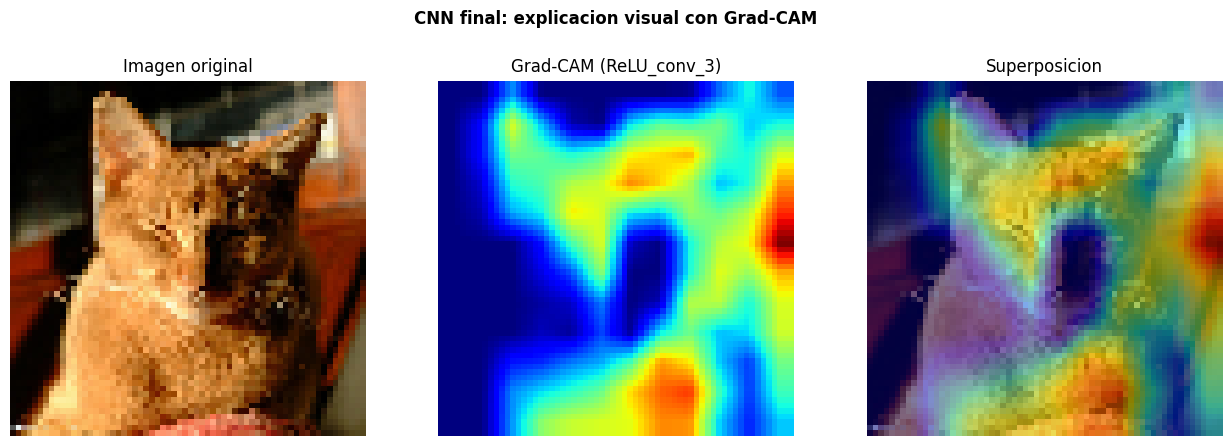

Imagen 3: real = Abyssinian | predicha = Abyssinian | probabilidad = 0.49


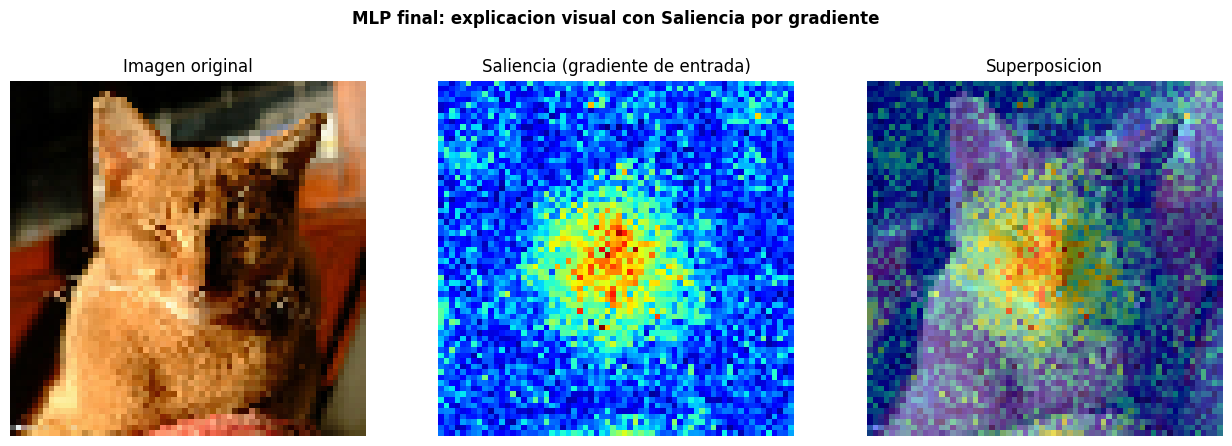

In [ ]:
indice_comparado = int(np.where(pred_cnn == y_test)[0][0]) if np.any(pred_cnn == y_test) else 0

for nombre_modelo, tipo in [
    ("CNN base", "CNN"),
    ("CNN final", "CNN"),
    ("MLP final", "MLP"),
]:
    explicar_modelo(
        resultados[nombre_modelo]["modelo"],
        tipo,
        X_test,
        y_test,
        class_names,
        nombre_modelo,
        indice_imagen=indice_comparado,
    )


**Interpretación de los mapas XAI**

En varios aciertos de la CNN, Grad-CAM destaca regiones
del gato, principalmente la cabeza y algunas partes
del cuerpo. Esto sugiere que esas zonas influyeron en las predicciones.

Sin embargo, también encontramos errores donde el
modelo destaca partes del gato y aun así confunde la
raza. Por ejemplo, un Abyssinian fue clasificado como
Bengal. En otro caso, un Birman fue confundido con
British Shorthair y el mapa también presentó
activaciones importantes sobre el entorno.

Al comparar una misma imagen, la CNN base clasificó
incorrectamente un Abyssinian como Maine Coon, mientras
que la CNN final y la MLP final acertaron, con probabilidades
de 0,40 y 0,49 respectivamente.

Aunque ambos modelos acertaron, estas probabilidades
muestran que las predicciones todavía presentan incertidumbre.
La saliencia de la MLP también muestra una distribución
más dispersa de píxeles relevantes que Grad-CAM.

Estos ejemplos ayudan a entender algunas predicciones,
pero no demuestran que el modelo reconozca correctamente
todas las características de una raza.

### 9.3 Auditoría de sesgos e implicancias éticas

La auditoría reutiliza los resultados de main(). Analizamos tres aspectos: balance entre razas, rendimiento por clase y diferencias según brillo. La presencia de cantidades similares de imágenes no garantiza el mismo F1 por raza; también pueden influir la semejanza visual, el fondo, el encuadre o la iluminación.

Los grupos Oscuras, Medias y Claras contienen cantidades parecidas de imágenes de prueba. Una diferencia entre sus accuracies es una señal exploratoria; no es un sesgo causal demostrado. Con unas pocas centenas de imágenes y una sola partición, no podemos asegurar que diferencias pequeñas se reproduzcan. Tampoco se analizan atributos protegidos de personas: aquí los grupos son categorías de gatos y una condición de captura.

**Implicancias éticas y de uso:** si una raza recibe sistemáticamente predicciones incorrectas, las personas podrían confiar en información equivocada. Para un eventual uso externo habría que comunicar incertidumbre y limitaciones, revisar de forma humana los casos importantes, comprobar la procedencia y condiciones de uso de las imágenes, y evitar publicar fotografías que contengan datos personales sin autorización. Este prototipo académico no debe utilizarse como única evidencia en decisiones importantes.


Sesgo de datos: desbalance entre razas en entrenamiento (max/min) = 1.09


,Brillo medio,Desviacion estandar
Raza,,
Maine_Coon,0.401,0.128
Bombay,0.402,0.123
Sphynx,0.424,0.151
Abyssinian,0.425,0.154
Egyptian_Mau,0.433,0.167
Birman,0.437,0.104
Bengal,0.439,0.114
Siamese,0.453,0.122
British_Shorthair,0.454,0.112


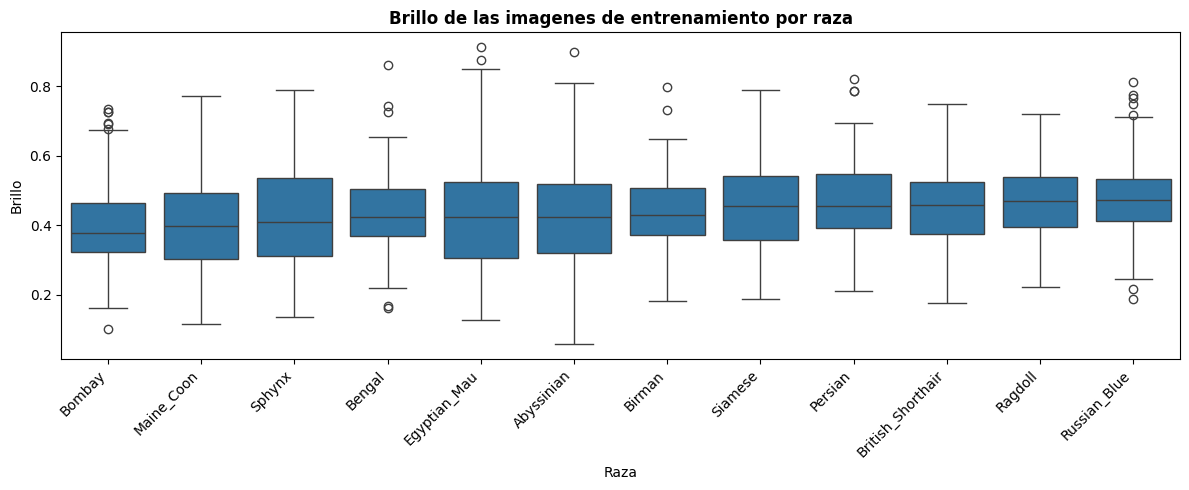

--- CNN final: accuracy por brillo ---


,Accuracy,Imagenes
Grupo,,
Oscuras,0.373,158
Medias,0.386,158
Claras,0.434,159


--- MLP final: accuracy por brillo ---


,Accuracy,Imagenes
Grupo,,
Oscuras,0.329,158
Medias,0.291,158
Claras,0.258,159


In [ ]:

def brillo_por_raza(X, y, class_names):
    """Brillo medio y desviacion estandar de las imagenes de entrenamiento por raza (sesgo de captura en los datos)"""
    brillo = X.mean(axis=(1, 2, 3))
    tabla = (pd.DataFrame({"Raza": [class_names[c] for c in y], "Brillo": brillo})
             .groupby("Raza")["Brillo"]
             .agg(["mean", "std"])
             .rename(columns={"mean": "Brillo medio", "std": "Desviacion estandar"})
             .sort_values("Brillo medio"))
    return tabla


def graficar_brillo_por_raza(X, y, class_names, nombre_fig):
    """Distribucion del brillo de las imagenes de entrenamiento, una caja por raza"""
    datos_grafico = pd.DataFrame({"Raza": [class_names[c] for c in y], "Brillo": X.mean(axis=(1, 2, 3))})
    orden = datos_grafico.groupby("Raza")["Brillo"].median().sort_values().index
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=datos_grafico, x="Raza", y="Brillo", order=orden)
    plt.xticks(rotation=45, ha="right")
    plt.title("Brillo de las imagenes de entrenamiento por raza", fontweight="bold")
    plt.tight_layout()
    guardar(nombre_fig)
    plt.show()




ratio_razas = class_distribution["Training"].max() / class_distribution["Training"].min()
print(f"Sesgo de datos: desbalance entre razas en entrenamiento (max/min) = {ratio_razas:.2f}")
display(brillo_por_raza(datos["X_train"], datos["y_train"], class_names).round(3))
graficar_brillo_por_raza(datos["X_train"], datos["y_train"], class_names, "11_brillo_por_raza")
sesgo_cnn = resultados["CNN final"]["auditoria"]["por_brillo"]
sesgo_mlp = resultados["MLP final"]["auditoria"]["por_brillo"]
print("--- CNN final: accuracy por brillo ---")
display(sesgo_cnn.round(3))
print("--- MLP final: accuracy por brillo ---")
display(sesgo_mlp.round(3))


In [ ]:

tabla_predicciones = pd.DataFrame({"Raza": class_names,
                                   "Casos reales": ev_cnn["matriz_confusion"].sum(axis=1)})
for nombre, ev in [("CNN final", ev_cnn), ("MLP final", ev_mlp)]:
    cm = ev["matriz_confusion"]
    tabla_predicciones[f"Predicciones {nombre}"] = cm.sum(axis=0)
    tabla_predicciones[f"Aciertos {nombre}"] = np.diag(cm)
    tabla_predicciones[f"Predicciones de más {nombre}"] = cm.sum(axis=0) - cm.sum(axis=1)
print("Un valor alto en 'Predicciones de más' indica una raza sobrepredicha (atractor)")
display(tabla_predicciones.sort_values("Predicciones de más CNN final", ascending=False))

razas_cnn = resultados["CNN final"]["auditoria"]["por_raza"]
raza_peor = razas_cnn.loc[razas_cnn["F1"].idxmin()]
raza_sobre = razas_cnn.loc[razas_cnn["Predicciones de más"].idxmax()]
brecha_brillo_cnn = float(sesgo_cnn["Accuracy"].max() - sesgo_cnn["Accuracy"].min())
print(f"CNN final: menor F1 por raza: {raza_peor['Raza']} "
      f"(F1={raza_peor['F1']:.3f}).")
print(f"CNN final: mayor sobrepredicción: {raza_sobre['Raza']} "
      f"({int(raza_sobre['Predicciones'])} predicciones / "
      f"{int(raza_sobre['Casos reales'])} casos reales).")
print(f"CNN final: rango de accuracy entre grupos de brillo={100*brecha_brillo_cnn:.1f} puntos "
      "porcentuales")


Un valor alto en 'Predicciones de más' indica una raza sobrepredicha (atractor)


,Raza,Casos reales,Predicciones CNN final,Aciertos CNN final,Predicciones de más CNN final,Predicciones MLP final,Aciertos MLP final,Predicciones de más MLP final
7,Persian,40,78,23,38,30,11,-10
2,Birman,40,62,19,22,63,11,23
9,Russian_Blue,40,59,22,19,56,15,16
8,Ragdoll,40,51,19,11,73,20,33
3,Bombay,37,39,30,2,54,29,17
4,British_Shorthair,40,41,14,1,39,8,-1
5,Egyptian_Mau,38,37,16,-1,28,9,-10
0,Abyssinian,40,31,11,-9,42,11,2
11,Sphynx,40,25,9,-15,22,5,-18
6,Maine_Coon,40,21,9,-19,18,6,-22


CNN final: menor F1 por raza: Sphynx (F1=0.277).
CNN final: mayor sobrepredicción: Persian (78 predicciones / 40 casos reales).
CNN final: rango de accuracy entre grupos de brillo=6.1 puntos porcentuales


**Interpretación ética de la auditoría**

La auditoría mostró diferencias de rendimiento entre las razas, incluso cuando el dataset presenta una distribución relativamente equilibrada.

En la CNN final, Sphynx obtuvo el menor F1 por clase, con 0,277. También observamos una sobrepredicción de Persian: el modelo realizó 78 predicciones de esta raza, aunque solamente había 40 imágenes reales. Esto muestra que algunas clases se reconocen con mayor dificultad que otras.

Respecto al brillo, la CNN final obtuvo una accuracy de 37,3% en imágenes oscuras, 38,6% en imágenes intermedias y 43,4% en imágenes claras. La diferencia máxima fue de aproximadamente 6,1 puntos porcentuales.

Estos resultados son exploratorios y no permiten asegurar que la iluminación sea la causa de los errores. Tampoco constituyen evidencia de discriminación hacia personas, ya que estamos clasificando razas de gatos.


**Resultados de la MLP final**

La MLP presentó un comportamiento diferente según
el brillo: obtuvo 32,9% de accuracy en imágenes oscuras,
29,1% en intermedias y 25,8% en claras.

La diferencia máxima fue de 7,1 puntos porcentuales,
superior a los 6,1 puntos observados en la CNN.
Además, la tendencia fue contraria: la CNN obtuvo
mejores resultados en imágenes claras, mientras que
la MLP funcionó mejor con imágenes oscuras.

También observamos una sobrepredicción de Ragdoll:
la MLP clasificó 73 imágenes como esa raza, aunque
solamente había 40 casos reales.

Estos resultados muestran que ambas arquitecturas
presentan diferencias de rendimiento, pero no se puede
afirmar que el brillo sea la causa sin realizar
experimentos adicionales.

**Implicancias éticas y medidas de mejora**

Los errores del modelo podrían entregar información incorrecta a los usuarios si se utilizara en una aplicación real. Por eso, no sería adecuado presentar sus predicciones como completamente confiables.

Para mejorar la solución, proponemos incorporar más fotografías variadas de las razas con peor desempeño, probar imágenes con diferentes fondos e iluminaciones y comprobar cómo cambian las predicciones bajo estas condiciones.

También sería importante verificar los permisos de uso de las imágenes, proteger la privacidad cuando se incorporen fotografías nuevas e informar las limitaciones del modelo.

En conclusión, la auditoría permitió identificar riesgos de confiabilidad que deben corregirse antes de utilizar el modelo fuera del contexto académico. Estas observaciones servirían para planificar una nueva iteración del Pipeline, sin modificar los resultados de prueba de esta evaluación.

## 10. Comparación objetiva MLP vs CNN

Las cuatro configuraciones comparten las mismas particiones. Comparamos métricas predictivas, curvas, generalización, parámetros, tiempos e interpretabilidad. Grad-CAM se utiliza en la CNN y saliencia por gradiente en la MLP. Son herramientas diferentes y sus mapas solo permiten una comparación cualitativa, no afirmar que una arquitectura es universalmente más explicable. Una sola partición y una ejecución por configuración final limitan la fuerza de las conclusiones.


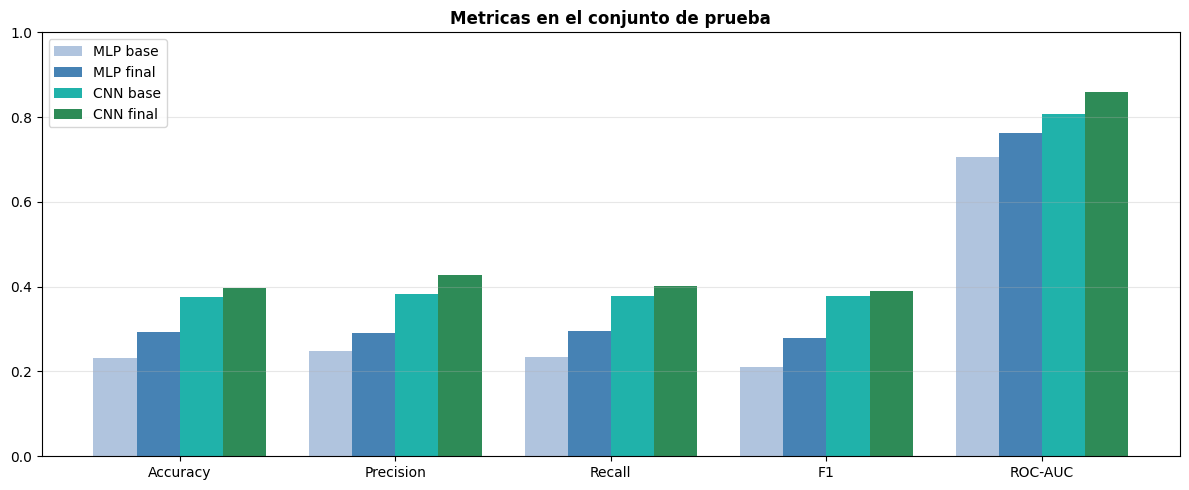

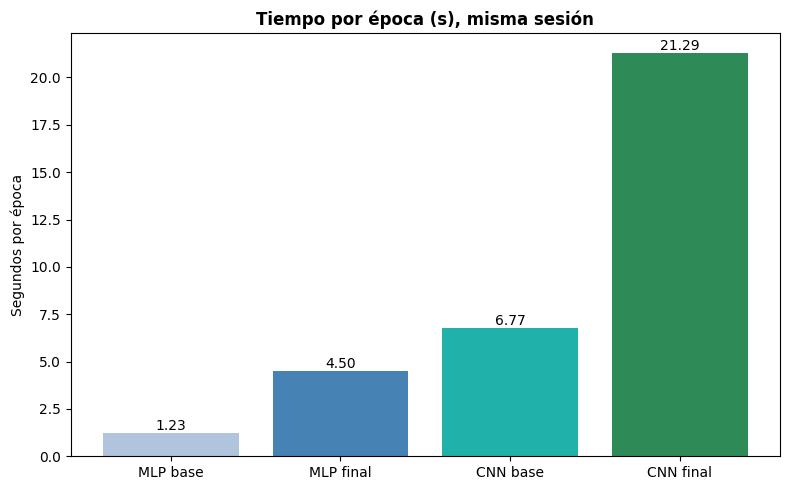

In [ ]:

METRICAS_GRAFICO = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
colores = {"MLP base": "lightsteelblue", "MLP final": "steelblue",
           "CNN base": "lightseagreen", "CNN final": "seagreen"}
modelos_orden = list(reporte_comparativo.index)

plt.figure(figsize=(12, 5))
x = np.arange(len(METRICAS_GRAFICO))
ancho = 0.2
for i, nombre in enumerate(modelos_orden):
    vals = reporte_comparativo.loc[nombre, METRICAS_GRAFICO].astype(float).values
    plt.bar(x + (i - 1.5) * ancho, vals, ancho, label=nombre, color=colores[nombre])
plt.xticks(x, METRICAS_GRAFICO)
plt.ylim(0, 1)
plt.title("Metricas en el conjunto de prueba", fontweight="bold")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
guardar("09a_metricas_prueba")
plt.show()

tpe = reporte_comparativo.loc[modelos_orden, "Tiempo/época (s)"].astype(float)
plt.figure(figsize=(8, 5))
plt.bar(modelos_orden, tpe.values, color=[colores[n] for n in modelos_orden])
for i, v in enumerate(tpe.values):
    plt.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.title("Tiempo por época (s), misma sesión", fontweight="bold")
plt.ylabel("Segundos por época")
plt.tight_layout()
guardar("09b_tiempo_por_epoca")
plt.show()


### 10.1 Tablas de resultados

La Tabla A contiene accuracy, precisión macro, recall macro, F1 macro y ROC-AUC. La Tabla B muestra parámetros, épocas, tiempo y brechas calculadas en modo inferencia. La figura de curvas ayuda a revisar la estabilidad de los entrenamientos.

In [ ]:
METRICAS_PRUEBA = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
COSTO_Y_DIAGNOSTICO = ["Parámetros", "Épocas", "Mejor época", "Tiempo entrenamiento (s)",
                       "Tiempo/época (s)", "Brecha train-prueba", "Diagnóstico curvas"]

print("Tabla A. Metricas en el conjunto de prueba")
display(reporte_comparativo[METRICAS_PRUEBA].astype(float).round(3))

print("Tabla B. Costo de entrenamiento y diagnostico de las curvas")
display(reporte_comparativo[COSTO_Y_DIAGNOSTICO].round(3))


Tabla A. Metricas en el conjunto de prueba


,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
MLP base,0.232,0.247,0.235,0.209,0.705
MLP final,0.293,0.290,0.295,0.279,0.763
CNN base,0.375,0.382,0.377,0.377,0.806
CNN final,0.398,0.428,0.401,0.390,0.859


Tabla B. Costo de entrenamiento y diagnostico de las curvas


,Parámetros,Épocas,Mejor época,Tiempo entrenamiento (s),Tiempo/época (s),Brecha train-prueba,Diagnóstico curvas
Modelo,,,,,,,
MLP base,1582028,30,30,36.956,1.232,0.296,brecha notable train-val: revisar sobreajuste
MLP final,1582604,24,19,108.090,4.504,0.117,brecha moderada train-val: revisar sobreajuste
CNN base,320172,30,30,203.236,6.775,0.625,brecha notable train-val: revisar sobreajuste
CNN final,685804,14,9,298.113,21.294,0.176,brecha notable train-val: revisar sobreajuste


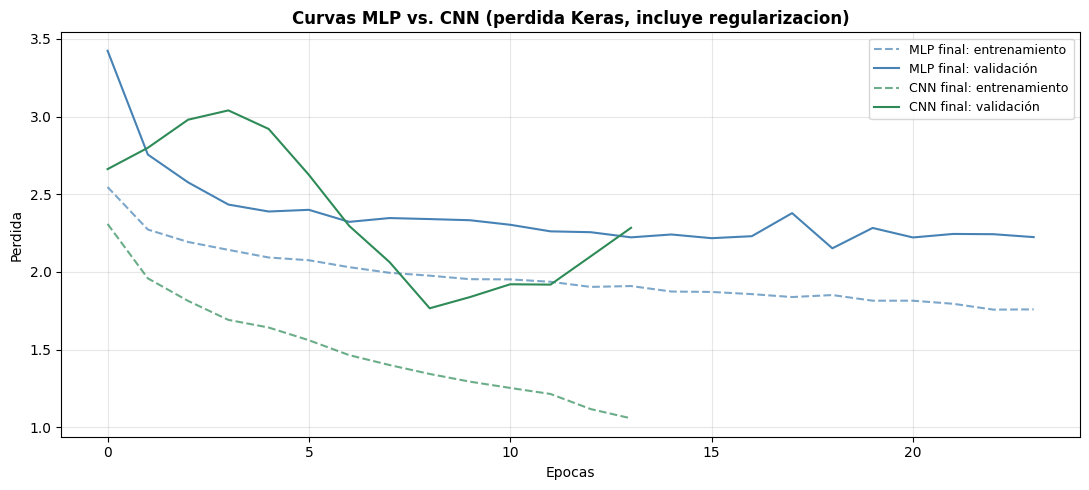

In [ ]:
plt.figure(figsize=(11, 5))
for nombre, color in [("MLP final", "steelblue"), ("CNN final", "seagreen")]:
    h = resultados[nombre]["history"]
    if h is None:
        print(f"{nombre}: sin historial de entrenamiento en esta sesion")
        continue
    plt.plot(h["loss"], "--", color=color, alpha=0.7, label=f"{nombre}: entrenamiento")
    plt.plot(h["val_loss"], "-", color=color, label=f"{nombre}: validación")
plt.title("Curvas MLP vs. CNN (perdida Keras, incluye regularizacion)", fontweight="bold")
plt.xlabel("Epocas")
plt.ylabel("Perdida")
plt.legend(fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
guardar("10_curvas_mlp_vs_cnn")
plt.show()

### 10.2 Diferencias entre arquitecturas

La MLP aplana los píxeles desde la entrada y aprende relaciones globales mediante capas densas. La CNN mantiene la estructura espacial durante sus bloques convolucionales y aprende patrones locales. Las tablas y los gráficos anteriores presentan las cifras de esta ejecución para accuracy, F1, ROC-AUC, parámetros, épocas y tiempos.

La CNN puede utilizar menos parámetros que la MLP y, al mismo tiempo, tardar más por época por el cálculo convolucional. El tiempo total también depende de cuántas épocas se ejecutaron antes de EarlyStopping.

**Explicabilidad:** para la CNN mostramos Grad-CAM, mientras que para la MLP usamos saliencia por gradiente sobre la entrada. Se calcula sobre una misma fotografía en la sección 9.2. Como los métodos resaltan información de manera diferente, no comparamos los colores o intensidades como si fueran una puntuación común. Esta inspección apoya la auditoría, pero no sustituye las métricas ni demuestra la causa de un error.


### 10.3 Selección técnica y ética del modelo final

**Regla establecida antes de mirar prueba:** seleccionar la arquitectura por menor cross-entropy de validación sobre las probabilidades, sin utilizar las métricas del test para cambiar la elección. La siguiente celda contrasta la elección con accuracy, F1, ROC-AUC, brechas de generalización, costo de entrenamiento y el resultado de auditoría. Los resultados de prueba informan, no optimizan.

También consideramos las limitaciones éticas. Un mejor promedio no elimina errores por raza; Grad-CAM en CNN y saliencia por gradiente en MLP ofrecen explicaciones visuales parciales; y las diferencias por brillo son exploratorias. Por ello, la solución recomendada sigue siendo un prototipo académico que requiere más validación para un uso real.


In [ ]:
def fila_criterios(nombre, resultado):
    """Criterios de decision de un modelo final, en el orden en que se aplican"""
    r = resultado
    m = r["evaluacion"]["metricas"]
    return {
        "CE de validacion (criterio)": r["res"]["val_ce"],
        "Perdida de validacion Keras (incluye L1/L2)": r["res"]["val_loss"],
        "Accuracy de validacion": r["res"]["val_acc"],
        "Accuracy de prueba": m["accuracy"],
        "F1 de prueba": m["f1_macro"],
        "ROC-AUC de prueba": m["roc_auc_ovr"],
        "Brecha train-prueba": r["diagnostico"]["train_acc_inferencia"] - m["accuracy"],
        "Tiempo/Época (s)": r["res"]["tiempo_s"] / r["res"]["epocas"],
        "Parámetros": r["modelo"].count_params(),
        "Herramienta XAI": r["explicacion"]["herramienta"],
    }


criterios = pd.DataFrame({n: fila_criterios(n, resultados[n]) for n in ["MLP final", "CNN final"]})
criterios.loc["Rango de accuracy entre grupos de sesgo de rendimiento"] = pd.Series({
    "MLP final": sesgo_mlp["Accuracy"].max() - sesgo_mlp["Accuracy"].min(),
    "CNN final": sesgo_cnn["Accuracy"].max() - sesgo_cnn["Accuracy"].min(),
})
display(criterios)

ganador_validacion = criterios.loc["CE de validacion (criterio)"].astype(float).idxmin()
print(f"Segun el criterio definido antes de mirar prueba (menor CE de validacion): {ganador_validacion}")
cnn_fin = resultados["CNN final"]["evaluacion"]["metricas"]
mlp_fin = resultados["MLP final"]["evaluacion"]["metricas"]
print(f"Prueba: CNN final accuracy={cnn_fin['accuracy']:.3f}, F1={cnn_fin['f1_macro']:.3f}, "
      f"AUC={cnn_fin['roc_auc_ovr']:.3f}; MLP final accuracy={mlp_fin['accuracy']:.3f}, "
      f"F1={mlp_fin['f1_macro']:.3f}, AUC={mlp_fin['roc_auc_ovr']:.3f}.")
print("Criterio de eleccion: Val CE; los valores de prueba no modifican la configuracion final")

,MLP final,CNN final
CE de validacion (criterio),2.151895,1.76591
Perdida de validacion Keras (incluye L1/L2),2.151895,1.76591
Accuracy de validacion,0.269129,0.398417
Accuracy de prueba,0.292632,0.397895
F1 de prueba,0.278992,0.39009
ROC-AUC de prueba,0.762948,0.858893
Brecha train-prueba,0.117388,0.176265
Tiempo/Época (s),4.503738,21.293767
Parámetros,1582604,685804
Herramienta XAI,Saliencia por gradiente,Grad-CAM


Segun el criterio definido antes de mirar prueba (menor CE de validacion): CNN final
Prueba: CNN final accuracy=0.398, F1=0.390, AUC=0.859; MLP final accuracy=0.293, F1=0.279, AUC=0.763.
Criterio de eleccion: Val CE; los valores de prueba no modifican la configuracion final


**Decisión técnica y ética.** La celda anterior identifica el ganador mediante la regla de validación fijada previamente. La comparación final permite ver si la elección es coherente con varias métricas de prueba, sin cambiar la regla después de observarlas.

**Interpretación:** la diferencia entre MLP y CNN debe leerse con accuracy, F1 macro, ROC-AUC, brechas, tiempos, Grad-CAM, saliencia por gradiente y errores por raza. Las mejoras pequeñas entre candidatos no se consideran ventajas demostradas: podrían cambiar al repetir los entrenamientos. La auditoría por brillo y sobrepredicción indica riesgos concretos de confiabilidad, por lo que se recomienda un uso supervisado y una validación adicional con imágenes nuevas y de procedencia autorizada.


## 11. Conclusiones

In [ ]:

registro_regularizacion.to_csv(os.path.join(REPORTES_DIR, "regularizacion.csv"), index=False)
registro_cnn.to_csv(os.path.join(REPORTES_DIR, "optimizacion_cnn.csv"), index=False)
registro_mlp.to_csv(os.path.join(REPORTES_DIR, "optimizacion_mlp.csv"), index=False)
reporte_comparativo.to_csv(os.path.join(REPORTES_DIR, "reporte_comparativo.csv"))

print("\nRESUMEN CALCULADO A PARTIR DE ESTA EJECUCION")
print("Tecnicas elegidas:", ", ".join(TECNICAS_SELECCIONADAS) or "ninguna")
print("Mejor optimización CNN:", resumen_cnn.loc[resumen_cnn["Elegido"] == "sí", "Configuración"].iloc[0])
print("Mejor optimización MLP:", resumen_mlp.loc[resumen_mlp["Elegido"] == "sí", "Configuración"].iloc[0])
print("Modelo elegido por validacion:", ganador_validacion)
for nombre in reporte_comparativo.index:
    r = reporte_comparativo.loc[nombre]
    print(f"{nombre}: accuracy prueba={r['Accuracy']:.3f}; F1 macro={r['F1']:.3f}; "
          f"ROC-AUC={r['ROC-AUC']:.3f}; brecha train-val (inferencia)={r['Brecha train-val']:.3f}; "
          f"tiempo={r['Tiempo entrenamiento (s)']:.1f}s")
for nombre, tabla in [("CNN final", sesgo_cnn), ("MLP final", sesgo_mlp)]:
    print(f"{nombre}: accuracy por brillo:", ", ".join(
        f"{grupo}={fila['Accuracy']:.3f} (n={int(fila['Imagenes'])})"
        for grupo, fila in tabla.iterrows()))
for nombre in ["CNN final", "MLP final"]:
    t = tabla_predicciones.sort_values(f"Predicciones de más {nombre}", ascending=False).iloc[0]
    print(f"Sobrepredicción principal {nombre}: {t['Raza']}: "
          f"{int(t[f'Predicciones {nombre}'])} predicciones frente a {int(t['Casos reales'])} reales")


for nombre in ["CNN final", "MLP final"]:
    ev = resultados[nombre]["evaluacion"]
    reporte = ev["classification_report_df"].drop(["macro avg", "weighted avg"], errors="ignore")
    peores = reporte.nsmallest(3, "f1-score")[["precision", "recall", "f1-score"]]
    print(f"\n{nombre}: tres clases con menor F1")
    display(peores.round(3))
    cm = ev["matriz_confusion"].copy()
    np.fill_diagonal(cm, 0)
    i, j = np.unravel_index(np.argmax(cm), cm.shape)
    print(f"Confusión más frecuente: {class_names[i]} → {class_names[j]} ({cm[i, j]} ejemplos)")
print("Registros CSV generados en:", REPORTES_DIR)



RESUMEN CALCULADO A PARTIR DE ESTA EJECUCION
Tecnicas elegidas: EarlyStopping, Data Augmentation, Batch Normalization
Mejor optimización CNN: Mejor de OFAT (una variable a la vez)
Mejor optimización MLP: Mejor de OFAT (una variable a la vez)
Modelo elegido por validacion: CNN final
MLP base: accuracy prueba=0.232; F1 macro=0.209; ROC-AUC=0.705; brecha train-val (inferencia)=0.330; tiempo=37.0s
MLP final: accuracy prueba=0.293; F1 macro=0.279; ROC-AUC=0.763; brecha train-val (inferencia)=0.141; tiempo=108.1s
CNN base: accuracy prueba=0.375; F1 macro=0.377; ROC-AUC=0.806; brecha train-val (inferencia)=0.636; tiempo=203.2s
CNN final: accuracy prueba=0.398; F1 macro=0.390; ROC-AUC=0.859; brecha train-val (inferencia)=0.176; tiempo=298.1s
CNN final: accuracy por brillo: Oscuras=0.373 (n=158), Medias=0.386 (n=158), Claras=0.434 (n=159)
MLP final: accuracy por brillo: Oscuras=0.329 (n=158), Medias=0.291 (n=158), Claras=0.258 (n=159)
Sobrepredicción principal CNN final: Persian: 78 prediccion

,precision,recall,f1-score
Sphynx,0.360,0.225,0.277
Bengal,0.500,0.200,0.286
Maine_Coon,0.429,0.225,0.295


Confusión más frecuente: Siamese → Birman (19 ejemplos)

MLP final: tres clases con menor F1


,precision,recall,f1-score
Siamese,0.188,0.075,0.107
Sphynx,0.227,0.125,0.161
British_Shorthair,0.205,0.200,0.203


Confusión más frecuente: British_Shorthair → Russian_Blue (17 ejemplos)
Registros CSV generados en: /content/reportes


### 11.1 Conclusiones y evaluación crítica del Pipeline

**Pipeline y continuidad del trabajo.** Reutilizamos las funciones vistas en clases: carga, EDA, normalización, construcción, entrenamiento, regularización, optimización, evaluación, auditoría y reporte. Separamos datos de entrenamiento, validación y prueba y registramos configuraciones, curvas y métricas. main() coordina el flujo final para cada modelo y la búsqueda de hiperparámetros se mantiene modular en optimizar_modelo().

**Regularización.** Comparamos las técnicas por separado y comprobamos una combinación candidata. El efecto más claro se observa cuando la CNN sin regularización tiene peor Val CE y una brecha notable entre entrenamiento y validación. No todas las técnicas mejoran simultáneamente accuracy, F1 y pérdida. La combinación y la inicialización se eligieron o descartaron según sus resultados de validación, no por preferencia.

**Optimización e incertidumbre.** Comparamos OFAT y Random Search utilizando validación. En esta ejecución, OFAT obtuvo la menor Val CE tanto en la CNN (1,7659) como en la MLP (2,1519). Sin embargo, las diferencias frente a Random Search fueron pequeñas y no podemos asegurar que se mantengan con otras semillas.

Además, al repetir una configuración equivalente obtuvimos exactamente la misma Val CE de 1,8189. Esto muestra consistencia, pero no permite estimar la variabilidad real del entrenamiento. Para una futura versión sería conveniente repetir los mejores candidatos con distintas semillas y comparar sus resultados.

**Comparación MLP/CNN.** La CNN final obtuvo los mejores resultados en prueba, con 39,8% de accuracy, 0,390 de F1 macro y 0,859 de ROC-AUC. La MLP final alcanzó 29,3%, 0,279 y 0,763, respectivamente.

La CNN final también mejoró respecto a la CNN base, aunque la diferencia de accuracy fue de aproximadamente 2,3 puntos porcentuales. La mejora más marcada estuvo en ROC-AUC y en la reducción del sobreajuste.

Sin embargo, la CNN requirió más tiempo de
entrenamiento: aproximadamente 298 segundos frente
a 108 segundos de la MLP final.

Por lo tanto, la CNN obtuvo mejores resultados
predictivos, pero con un mayor costo computacional.

Seleccionamos la CNN por su menor cross-entropy de validación y por los resultados obtenidos en las métricas de evaluación. Esta elección también considera las limitaciones encontradas en la auditoría y las explicaciones XAI. No significa que el modelo sea suficientemente confiable para utilizarse sin validación adicional.

**Fortalezas.** La modularidad facilita repetir experimentos y auditar resultados; la misma partición permite comparaciones; el registro de Val CE, F1, ROC-AUC, curvas y matrices evita depender únicamente de accuracy. Grad-CAM en la CNN y la saliencia por gradiente en la MLP agregan una revisión visual de algunas decisiones; los dos métodos no se comparan numéricamente.

**Limitaciones y riesgos.** Las imágenes de 64 × 64 pueden perder información útil; solo usamos una partición y un presupuesto acotado de búsqueda; y los ejemplos XAI no explican todas las predicciones. EarlyStopping y la selección de hiperparámetros utilizan el mismo conjunto de validación, por lo que la Val CE seleccionada puede ser optimista debido a la reutilización de esos datos. No usamos el conjunto de prueba para elegir las configuraciones; aun así, ajustar modelos después de revisar sus errores en ese mismo test invalidaría su independencia. El brillo es solo una aproximación a las condiciones de captura y no permite atribuir causas.

**Implicancias éticas.** Los errores por raza pueden afectar la fiabilidad de lo que se comunica a quien use una aplicación. Debemos mostrar las limitaciones, evitar presentar una predicción como certeza, verificar el permiso de uso de las imágenes y proteger la privacidad cuando se incorporen fotografías nuevas. Este clasificador experimental no debe utilizarse como única fuente de decisiones relevantes; se requiere revisión humana cuando corresponda. Las diferencias por clase se refieren a razas de gatos, no constituyen evidencia de discriminación hacia personas.

**Próxima iteración.** Repetir los candidatos con varias semillas y reportar media y desviación; evaluar mayor resolución y fotografías de razas difíciles; comprobar el efecto de fondo e iluminación con pruebas controladas; ampliar el análisis explicable; y reservar datos nuevos para una evaluación final independiente. Estas mejoras son viables y responden directamente a los problemas observados.

En conjunto, el Pipeline permite seleccionar y justificar una arquitectura **entre las evaluadas**, pero aún presenta límites de generalización y robustez que deben reconocerse antes de un uso externo.


### Matriz de Responsabilidades

| Integrante | Tareas Realizadas |
|---|---|
| **Agustín Fernández** | Preparación y preprocesamiento del dataset, análisis exploratorio (EDA), validación de particiones y pruebas de técnicas de regularización. |
| **Sebastián Salgado** | Implementación y ajuste de la CNN, optimización de hiperparámetros mediante OFAT y Random Search, análisis de curvas de aprendizaje. |
| **Eduardo Uribe** | Entrenamiento y evaluación comparativa de MLP y CNN, análisis de métricas, auditoría de sesgos, Grad-CAM y documentación final del Pipeline. |